# KNN（1967）

- **核心原理**：距離最近的 K 個鄰居投票
- **變體**：距離加權投票；KD-Tree、Ball Tree；近似最近鄰（FAISS、HNSW）
- **推薦資料集**：Digits（1,797 張 8×8 手寫數字、64 個像素特徵、灰階 0–16、10 類）

本章依照 README 的「每章標準流程」：EDA → Baseline → 手寫模型 → 套件實作 → 調參 → 測試集評估 → 診斷 → 本章小結。

KNN 和前三章最大的不同：**它沒有參數要學**。`fit` 只是把訓練資料存起來（lazy learning），所有計算都發生在 `predict`。
因此這一章的重點從「怎麼最佳化」換成「**距離怎麼定義**」：特徵尺度、距離種類、維度，決定了誰是誰的鄰居。

---
## 1. 資料與探索性資料分析（EDA）

觀察直接寫在每格程式最上面的註解（`# 觀察：`）。

In [66]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from ml_dl_llm.data import load_digits

X_train, X_test, y_train, y_test = load_digits()
train = X_train.assign(label=y_train)

print("train / test：", X_train.shape, X_test.shape)
print("欄位名稱：", X_train.columns[:4].tolist(), "...（pixel_列_行）")

train / test： (1437, 64) (360, 64)
欄位名稱： ['pixel_0_0', 'pixel_0_1', 'pixel_0_2', 'pixel_0_3'] ...（pixel_列_行）


In [67]:
# 觀察：64 個欄位都是 float64、沒有缺值，但實際上只出現 0–16 共 17 種「整數」值。
#   原因：原始資料是 32×32 的黑白點陣圖，切成 8×8 個 4×4 的小格，每格數「有幾個黑點」→ 0–16。
#   → 不需要補值或編碼；整數值使平方距離也是整數，鄰居之間容易出現距離平手（TODO 8 (1)）。
print("型態：", X_train.dtypes.value_counts().to_dict())
print("缺值：", int(X_train.isna().sum().sum()))
print("出現過的像素值：", np.unique(X_train.to_numpy()))

型態： {dtype('float64'): 64}
缺值： 0
出現過的像素值： [ 0.  1.  2.  3.  4.  5.  6.  7.  8.  9. 10. 11. 12. 13. 14. 15. 16.]


In [68]:
# 觀察：（這格是「類別」的分布，不是像素值）10 類各 139–146 筆，每類約 10%，幾乎完全平衡。
#   load_digits 已分層切分，train／test 比例一致。
#   → 「永遠猜同一類」的 accuracy 約 0.10；accuracy 足以當主要指標，不必像第三章(不平衡樣本)另外盯某一類的 recall。
display(
    y_train.value_counts()
    .sort_index()
    .to_frame("count")
    .assign(ratio=y_train.value_counts(normalize=True).sort_index().round(3))
    .T
)

target,0,1,2,3,4,5,6,7,8,9
count,142.000,146.000,142.000,146.000,145.000,145.000,145.000,143.0,139.000,144.0
ratio,0.099,0.102,0.099,0.102,0.101,0.101,0.101,0.1,0.097,0.1


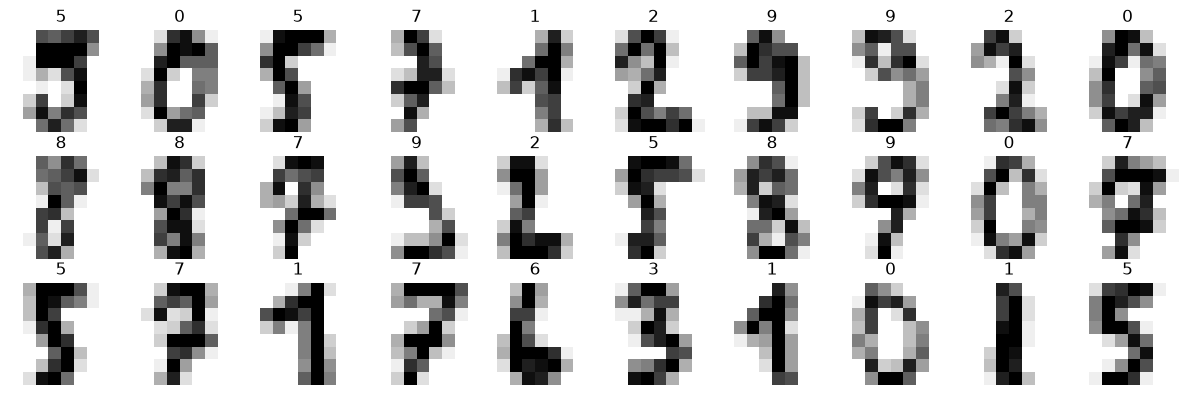

In [69]:
# 前 30 張訓練影像
# 觀察：數字已置中、大小大致一致（資料做過前處理），但同一類的寫法差異明顯：
#   7 有沒有中間橫線、1 有沒有頂端斜鉤／底線、筆畫粗細與傾斜不同；8×8 解析度很低，少數樣本人眼也不易辨認
#   （例如第 2 列第 4 張標成 9，看起來更像 5）。
#   → 像素距離對「位置偏移、粗細、寫法」很敏感，第 7 節診斷要回頭檢查錯誤是不是來自這裡。
fig, axes = plt.subplots(3, 10, figsize=(12, 4))
for ax, img, lab in zip(axes.ravel(), X_train.to_numpy(), y_train):
    ax.imshow(img.reshape(8, 8), cmap="gray_r", vmin=0, vmax=16)
    ax.set_title(lab)
    ax.axis("off")
fig.tight_layout()
plt.show()

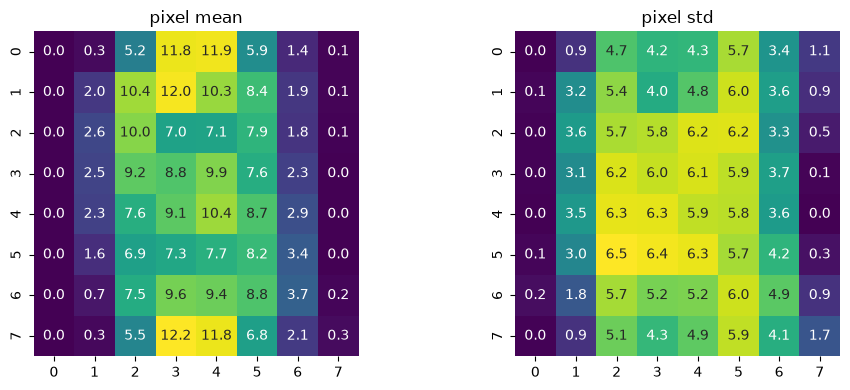

標準差 = 0 的像素： ['pixel_0_0', 'pixel_4_0', 'pixel_4_7']
標準差 < 0.5 的像素數： 12
這些低變異像素的非零比例： {'pixel_0_0': 0.0, 'pixel_1_0': 0.004, 'pixel_2_0': 0.001, 'pixel_2_7': 0.019, 'pixel_3_0': 0.001, 'pixel_3_7': 0.003, 'pixel_4_0': 0.0, 'pixel_4_7': 0.0, 'pixel_5_0': 0.005, 'pixel_5_7': 0.011, 'pixel_6_0': 0.002, 'pixel_7_0': 0.001}


In [70]:
# 每個像素的平均值與標準差（排成 8×8，跟影像位置對應）
# 觀察：最左、最右兩欄（col 0、7）的 mean、std 都接近 0 —— 數字置中後，筆畫很少碰到左右邊緣；
#   上下兩列的中間仍有筆畫（數字是直立的長方形）。
#   3 個像素恆為 0（pixel_0_0、pixel_4_0、pixel_4_7）；12 個 std < 0.5，非零比例都 < 2%（多數 < 0.5%）。
#   變異集中在中間 col 2–5。raw 距離下，每個像素對平方距離的平均貢獻 = 2·Var(xⱼ)，
#   所以這些低變異的邊緣像素在 raw 距離中幾乎被自動忽略（TODO 1 (1) 的關鍵）。
#   注意：變異大不等於「能區分類別」，但變異接近 0 的像素一定幫不上忙。
pix_mean = X_train.mean().to_numpy().reshape(8, 8)
pix_std = X_train.std().to_numpy().reshape(8, 8)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, M, title in [
    (axes[0], pix_mean, "pixel mean"),
    (axes[1], pix_std, "pixel std"),
]:
    sns.heatmap(
        M, annot=True, fmt=".1f", cmap="viridis", ax=ax, cbar=False, square=True
    )
    ax.set_title(title)
fig.tight_layout()
plt.show()

std = X_train.std()
print("標準差 = 0 的像素：", std.index[std == 0].tolist())
print("標準差 < 0.5 的像素數：", int((std < 0.5).sum()))
print(
    "這些低變異像素的非零比例：",
    (X_train.loc[:, std < 0.5] > 0).mean().round(3).to_dict(),
)

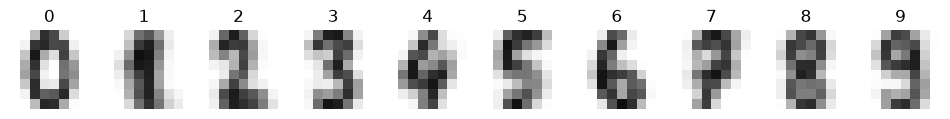

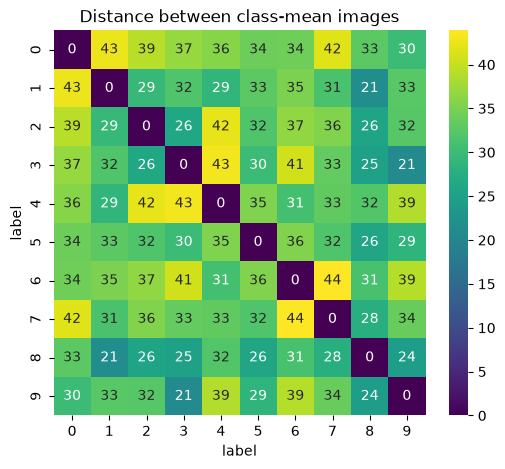

平均影像最接近的 5 對： [(3, 9, 20.9), (1, 8, 21.4), (8, 9, 24.2), (3, 8, 25.1), (2, 8, 25.6)]


In [71]:
# 每一類的平均影像
# 觀察：平均影像最接近的 5 對：(3,9) 20.9、(1,8) 21.4、(8,9) 24.2、(3,8) 25.1、(2,8) 25.6 —— 最接近的其實是 3 和 9。
#   8 出現在其中 4 對：8 的筆畫覆蓋整個中央區域，平均影像像一團「中央的墨水」，與多數數字的平均影像重疊都大。
#   平均影像是模糊的：同一類有多種寫法時（例如 1、7），平均起來不像任何一張真實影像（TODO 1 (3)）。
fig, axes = plt.subplots(1, 10, figsize=(12, 1.8))
class_means = train.groupby("label").mean()
for ax, (lab, row) in zip(axes, class_means.iterrows()):
    ax.imshow(row.to_numpy().reshape(8, 8), cmap="gray_r", vmin=0, vmax=16)
    ax.set_title(lab)
    ax.axis("off")
plt.show()

# 類別平均影像之間的歐氏距離：越小代表兩類的「典型樣子」越像
from sklearn.metrics import pairwise_distances

cm_dist = pd.DataFrame(
    pairwise_distances(class_means), index=class_means.index, columns=class_means.index
)
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(cm_dist, annot=True, fmt=".0f", cmap="viridis", ax=ax)
ax.set_title("Distance between class-mean images")
plt.show()
pairs = (
    cm_dist.where(np.triu(np.ones(cm_dist.shape, dtype=bool), k=1))
    .stack()
    .sort_values()
)
print(
    "平均影像最接近的 5 對：",
    [(int(a), int(b), round(v, 1)) for (a, b), v in pairs.head(5).items()],
)

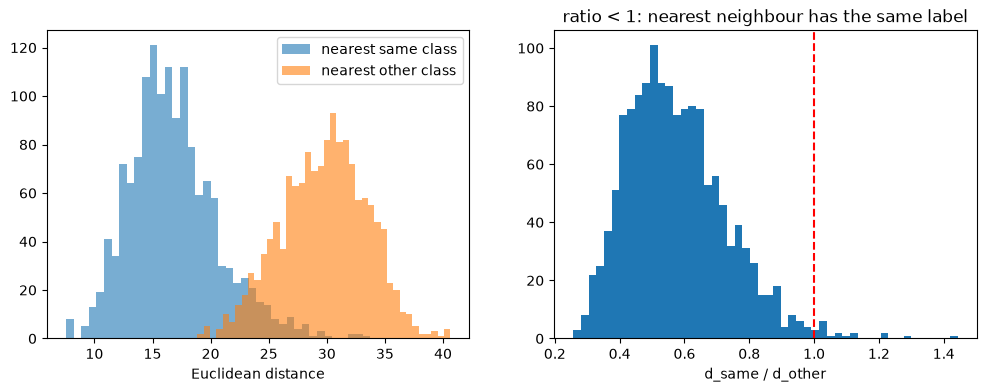

ratio < 1 的比例：0.9882   ratio ≥ 1 的筆數：17
全部樣本的最近鄰距離：中位數 16.4 ；任兩點距離的中位數 49.0


In [72]:
# KNN 專屬的 EDA：每一筆訓練樣本「最近的同類」vs「最近的異類」距離（不算自己）
# ratio = 最近同類距離 / 最近異類距離；ratio < 1 代表它最近的鄰居跟它同類
# 觀察：98.8% 的樣本最近的鄰居是同類，只有 17 筆 ratio ≥ 1。
#   最近鄰距離中位數 16.4，遠小於任兩點距離的中位數 49.0 → 每個點附近幾乎都有很近的同類，局部結構很強，很適合 KNN。
#   錯誤會集中在少數「邊界」樣本：它們離某個異類樣本比離所有同類都近。
#   這些樣本 1-NN 一定錯；k 大一點時，若其餘鄰居多數是同類，多數決可以救回一部分。
D_eda = pairwise_distances(X_train)  # (1437, 1437) 歐氏距離
np.fill_diagonal(D_eda, np.inf)
same = y_train.to_numpy()[:, None] == y_train.to_numpy()[None, :]
d_same = np.where(same, D_eda, np.inf).min(axis=1)
d_other = np.where(~same, D_eda, np.inf).min(axis=1)
ratio = d_same / d_other

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(d_same, bins=40, alpha=0.6, label="nearest same class")
axes[0].hist(d_other, bins=40, alpha=0.6, label="nearest other class")
axes[0].set_xlabel("Euclidean distance")
axes[0].legend()
axes[1].hist(ratio, bins=50)
axes[1].axvline(1, color="r", ls="--")
axes[1].set_xlabel("d_same / d_other")
axes[1].set_title("ratio < 1: nearest neighbour has the same label")
plt.show()
print(
    f"ratio < 1 的比例：{(ratio < 1).mean():.4f}   ratio ≥ 1 的筆數：{(ratio >= 1).sum()}"
)
print(
    "全部樣本的最近鄰距離：中位數",
    round(float(np.median(np.minimum(d_same, d_other))), 1),
    "；任兩點距離的中位數",
    round(float(np.median(D_eda[np.isfinite(D_eda)])), 1),
)

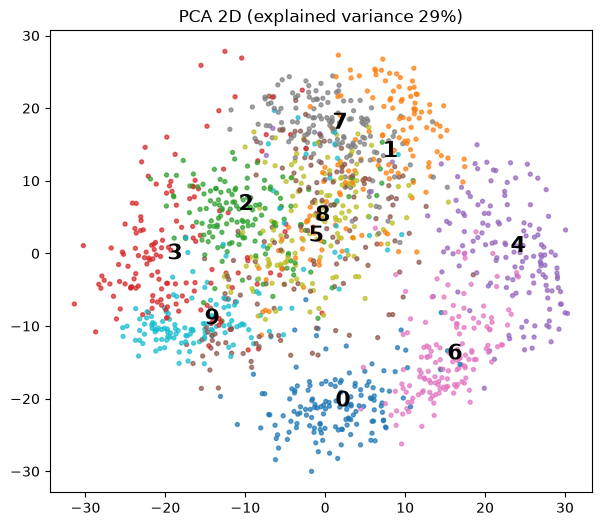

In [73]:
# 只為了「看」：用 PCA 投影到 2 維（PCA 是第 14 章的主題，這裡先當工具用）
# 觀察：2 維只保留約 28.5% 的變異（PC1 14.8%、PC2 13.7%；要 21 個主成分才到 90%）。
#   0、4、6、3 大致各自成團（4 與 6 相鄰）；中央的 1、7、8、5、2 嚴重重疊，8 散布在中央、與多類交錯。
#   8 分散的原因較可能是「與多類共用筆畫、同類內差異也大」，投影時就落在多類之間；
#   但這只是 2 維的樣子，不能直接推論 64 維也分不開（TODO 1 (4)）。
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=42).fit(X_train)
Z = pca.transform(X_train)
fig, ax = plt.subplots(figsize=(7, 6))
sc = ax.scatter(Z[:, 0], Z[:, 1], c=y_train, cmap="tab10", s=8, alpha=0.7)
for lab in range(10):
    cx, cy = np.median(Z[y_train.to_numpy() == lab], axis=0)
    ax.text(cx, cy, str(lab), fontsize=16, weight="bold")
ax.set_title(f"PCA 2D (explained variance {pca.explained_variance_ratio_.sum():.0%})")
plt.show()

### TODO 1（問答）EDA 小結

> **(1)** 64 個特徵的「單位」都一樣（灰階 0–16），但有 3 個像素永遠是 0、12 個像素標準差 < 0.5。KNN 只靠距離做決定，要不要標準化？如果用 StandardScaler，這些幾乎不變的邊緣像素會發生什麼事？（先寫下你的預測，3C 的實驗 2 會驗證；對照第三章「標準化是必要的」的結論）

**預測**：不該標準化，標準化會讓 KNN 變差。

**修正**：標準化只是平移＋縮放，不改變分布形狀；它改變的是每個特徵在距離中的「權重」。

- raw 距離下，像素 $j$ 對平方距離的平均貢獻 $= 2\,\mathrm{Var}(x_j)$。邊緣像素變異接近 0 → 幾乎不影響距離，這剛好是對的：它們幾乎不帶字形資訊。在這份資料裡，原始尺度（變異大小）本身就代表「資訊量」。
- 標準化後每個像素的平均貢獻都變成 2，12 個幾乎不變的像素拿到跟中央像素一樣的份量；而且它們偶爾出現的非零值會變成極端的 $z$ 值：pixel_7_0 只有約 0.1% 的樣本是 1，標準化後 $1 \to 37.9$ 個標準差，單一像素就貢獻 $37.9^2 \approx 1{,}400$ 的平方距離，遠大於典型最近鄰的平方距離（$16.4^2 \approx 270$）→ 一個邊緣雜點就足以決定誰是鄰居。
- 恆為 0 的 3 個像素：std = 0，StandardScaler 讓它維持 0，不影響距離。

**對照第三章**：那裡標準化是為了梯度下降的條件數與 L2 懲罰的公平性；KNN 沒有最佳化，「縮放」等於在選距離的權重。特徵單位不同時（Breast Cancer 的 area $\sim 10^3$ vs smoothness $\sim 0.1$）必須標準化，否則距離被大單位特徵壟斷；單位相同、且變異大小本身有意義時（像素），標準化反而放大雜訊。

> **(2)** 「最近同類 / 最近異類」的 ratio < 1 的比例，其實就是某個模型在某種驗證方式下的 accuracy。是哪個模型、哪種驗證？為什麼？（3C 的 TODO 9 會用程式驗證這個數字）

**1-NN 在 leave-one-out（LOO）交叉驗證下的 accuracy（0.9882）。**

- `fill_diagonal(inf)` 讓每一筆找鄰居時排除自己 —— 等於「拿掉這一筆、用其他 $n-1$ 筆預測它」，就是 LOO。
- 1-NN 直接採用最近鄰的標籤：最近鄰是同類 ⇔ $d_\text{same} < d_\text{other}$ ⇔ ratio < 1 ⇔ 1-NN 猜對。
- 小細節：ratio = 1（最近同類與最近異類距離平手）時，預測取決於平手怎麼破；這份資料沒有影響。

> **(3)** 從類別平均影像與距離表看，你預期哪幾對數字最容易被 KNN 搞混？「平均影像接近」一定代表「容易搞混」嗎？（第 7 節對照混淆矩陣）

預期與 8 有關的組合（1–8、8–9、3–8、2–8），以及距離表上最接近的 3–9（20.9）。

「平均影像接近」**不一定**代表「容易搞混」：

- KNN 比的是「個別樣本」，不是平均影像。會不會搞混取決於兩類的點雲在邊界上有沒有交錯，不是兩個中心離多近：兩類中心近、但各自很集中，仍可能分得很開。
- 反過來，一類內若有多種寫法，平均影像是模糊的混合、不像任何真實樣本；其中某一種寫法可能很貼近另一類的樣本，即使兩類的平均影像離得遠。
- → 平均影像的距離是 NearestCentroid 的視角，只是粗略的線索。

> **(4)** PCA 2 維圖上好幾類重疊，可是 (2) 的比例很高。為什麼 2 維投影上的重疊，不代表 64 維空間中也重疊？

重疊來自投影丟掉的資訊：

- 2 維只保留約 28.5% 的變異，其餘 62 個方向的差異全部被壓掉；在丟掉的方向上相距很遠的兩點，投影後可能疊在一起。
- 正交投影只會讓距離變短、不會變長：$\|P(a-b)\| \le \|a-b\|$。2 維分得開 ⇒ 64 維一定分得開，反之不成立。所以低維的重疊不是高維重疊的證據。
- KNN 只需要「局部」的鄰居同類（ratio < 1），不需要整類在全域上被分開。

（多看一個維度不是關鍵：3 維也只保留少部分變異，仍會有重疊。）

---
## 2. Baseline

10 類大致平衡，accuracy 的起點約 0.1。除了 Dummy，再加一個「最簡單的距離模型」**NearestCentroid**：
每一類只記一個平均影像，預測時找最近的類別中心 —— 等於「每類只有 1 個代表點」的最近鄰。

指標：
- **accuracy**：主要指標（類別平衡，accuracy 夠用）
- **log loss**：機率品質。KNN 的機率是「鄰居得票比例」，會在第 5 節看到它的特殊問題

In [75]:
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.neighbors import NearestCentroid
from sklearn.base import BaseEstimator

# 整章共用的 5-fold（分層、打亂、固定 seed）
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)


def cv_summary(model: BaseEstimator, X: pd.DataFrame = X_train, y: pd.Series = y_train) -> dict[str, str]:
    """5-fold CV。回傳 {"accuracy": "平均 ± 標準差", "log_loss": "平均 ± 標準差"}；沒有 predict_proba 的模型 log_loss 為 "—"。"""
    scoring = {"accuracy": "accuracy"}
    if hasattr(model, "predict_proba"):
        scoring["log_loss"] = "neg_log_loss"
    s = cross_validate(model, X, y, cv=cv, scoring=scoring)
    out = {
        "accuracy": f"{s['test_accuracy'].mean():.4f} ± {s['test_accuracy'].std():.4f}",
        "log_loss": "—",
    }
    if "log_loss" in scoring:
        v = -s["test_log_loss"]
        out["log_loss"] = f"{v.mean():.4f} ± {v.std():.4f}"
    return out


# NearestCentroid 的 UserWarning（某些像素在類別內標準差為 0）來自 EDA 看到的常數像素，可以忽略
baseline = pd.DataFrame(
    {
        "Dummy most_frequent": cv_summary(DummyClassifier(strategy="most_frequent")),
        "Dummy prior": cv_summary(DummyClassifier(strategy="prior")),
        "NearestCentroid": cv_summary(NearestCentroid()),
    }
).T
display(baseline)

/Users/cya/ml-dl-llm/.venv/lib/python3.12/site-packages/sklearn/neighbors/_nearest_centroid.py:241: UserWarning: self.within_class_std_dev_ has at least 1 zero standard deviation.Inputs within the same classes for at least 1 feature are identical.
  warnings.warn(
/Users/cya/ml-dl-llm/.venv/lib/python3.12/site-packages/sklearn/neighbors/_nearest_centroid.py:241: UserWarning: self.within_class_std_dev_ has at least 1 zero standard deviation.Inputs within the same classes for at least 1 feature are identical.
  warnings.warn(
/Users/cya/ml-dl-llm/.venv/lib/python3.12/site-packages/sklearn/neighbors/_nearest_centroid.py:241: UserWarning: self.within_class_std_dev_ has at least 1 zero standard deviation.Inputs within the same classes for at least 1 feature are identical.
  warnings.warn(
/Users/cya/ml-dl-llm/.venv/lib/python3.12/site-packages/sklearn/neighbors/_nearest_centroid.py:241: UserWarning: self.within_class_std_dev_ has at least 1 zero standard deviation.Inputs within the same cla

,accuracy,log_loss
Dummy most_frequent,0.1009 ± 0.0002,32.4067 ± 0.0062
Dummy prior,0.1009 ± 0.0002,2.3025 ± 0.0000
NearestCentroid,0.9081 ± 0.0097,1.5589 ± 0.3542


### TODO 2（問答）

> **(1)** Dummy prior 的 log loss 約 2.30，用類別比例手算出來（提示：10 類幾乎平衡）。這個數字在 10 類問題裡代表什麼？（對照第三章二元的 0.66）

Dummy prior 的 `predict_proba` 對每一筆都輸出同一個 10 維向量 = 訓練集的類別比例 $q = (q_0, \dots, q_9)$，每個 $q_k \approx 0.1$（0.097–0.102）。

**修正**：不是 `[0.1, 0.9]` —— 那是二元的寫法；而且是「每一筆都付」約 $-\ln 0.1 = 2.303$，不是「最多付」。

$$\text{平均 log loss} = -\sum_k q_k \ln q_k = \text{標籤分布的熵} = 2.3025 \quad(\text{完全平衡時} = \ln 10 = 2.3026)$$

意義：

- 這是「完全不看 $x$」時 log loss 能達到的最小值，也是 10 類問題的實際 baseline；模型要低於它，才代表特徵提供了資訊。
- $K$ 類完全平衡時熵 $= \ln K$，是 $K$ 類的最大值：$e^{2.30} = 10$，相當於「在 10 個選項之間完全猶豫」（perplexity = 10）。
- 對照第三章：二元的上限是 $\ln 2 = 0.693$，乳癌資料 1.7 : 1 不平衡所以只有 0.66。→ **log loss 的數值大小取決於類別數與類別比例，跨資料集不能直接比，要和各自的 baseline 比。**

補充：

- most_frequent 的 32.4 = 每筆非多數類的樣本付 $-\ln(\varepsilon) \approx 36.04$，乘上它們的比例 0.898 → 32.4（第三章 TODO 2 的 $\log 0$ 問題）。
- NearestCentroid 的 accuracy 0.91，log loss 卻有 1.56 ± 0.35，只比 2.30 好一些：它的機率由類別內標準差估出，很容易「有把握地錯」—— accuracy 高不代表機率可信。

> **(2)** NearestCentroid 只用 10 個平均影像就有約 0.9 的 accuracy。它對「每一類資料的形狀」做了什麼假設？哪一種資料會讓這個假設失敗（想一個同一類有兩種寫法的數字）？KNN 怎麼放寬這個假設？

**假設**：每一類是「圍繞一個中心、單一一團、各方向散布程度差不多（球狀）」的點雲，各類的散布程度也相近。在這個假設下，平均影像就是該類最好的代表，決策規則「離哪個中心近就是哪類」合理。決策邊界是兩兩中心連線的垂直平分面 → 分段線性（10 個中心的 Voronoi 分割）。（等價於「各類是共變異數相同且為 $\sigma^2 I$ 的高斯、先驗相同」時的貝氏分類器；LDA 是它的推廣。）

**失敗的例子**：同一類有兩種以上寫法（多峰，multimodal），例如 7 有沒有中間橫線、1 有沒有頂端斜鉤／底線：

- 類別中心是兩種寫法的平均 = 一張不像任何真實樣本的模糊影像，落在兩群之間；
- 某一種寫法的樣本，可能離其他類的中心比離自己類的模糊中心還近 → 被誤判。
- 其他會失敗的形狀：細長（非球狀）的類別、彎曲的類別、散布程度差很多的兩類。

**修正**：問題不是「C 的樣本像 A 或 B」—— 那是類別本身重疊，KNN 也救不了；而是 C 的每種寫法都很好辨認，但用「一個平均點」代表整類時資訊被抹掉了。

**KNN 如何放寬**：不做任何形狀假設，把每一筆訓練資料都當成代表點（prototype）。只要查詢點附近的鄰居大多同類，不論那一類是多峰、彎曲還是細長都能處理；邊界由資料局部決定，可以任意彎曲。

**修正**：KNN 取的是固定「個數」$k$ 個最近鄰，不是「特定距離內」的點 —— 後者是 RadiusNeighborsClassifier。

- 代價：要存下全部資料、預測時要算所有距離；邊界由少數點決定，變異較大，靠 $k$ 控制平滑程度。
- 光譜：NearestCentroid（每類 1 個代表點）← 每類多個代表點（例如每類各做 K-Means）→ KNN（每筆都是代表點）。

---
## 3. 手寫模型

### 3A. 距離矩陣

KNN 的計算量幾乎都在「每個查詢點對每個訓練點的距離」。n_test × n_train 個距離，用 for 迴圈會非常慢。

把平方距離展開：

‖a − b‖² = ‖a‖² + ‖b‖² − 2 a·b

- ‖a‖²、‖b‖² 各算一次（向量），交叉項 a·b 一次矩陣乘法 `A @ B.T` 全部算完 → 這也是 sklearn `euclidean_distances` 的做法。
- 排序只需要**平方距離**（平方根是單調函數，不改變誰比較近），平方根只在需要真正的距離時（例如距離加權）才算。

In [77]:
import time
from numpy.typing import ArrayLike
from scipy.spatial.distance import cdist

Xtr = X_train.to_numpy(dtype=float)
Xte = X_test.to_numpy(dtype=float)
ytr = y_train.to_numpy()
yte = y_test.to_numpy()


def pairwise_sq_dists(A: ArrayLike, B: ArrayLike) -> np.ndarray:
    """平方歐氏距離矩陣。A (n, d)、B (m, d) → D (n, m)，D[i, j] = ‖A[i] − B[j]‖²。"""
    A = np.asarray(A, dtype=float)
    B = np.asarray(B, dtype=float)
    # TODO 3（程式）：向量化的平方距離矩陣
    #   - 用 ‖a‖² + ‖b‖² − 2a·b；‖a‖² 用 (A**2).sum(axis=1)，交叉項用 A @ B.T
    #   - 用 [:, None]／[None, :] 把 (n,) 與 (m,) 的向量廣播成 (n, m)
    #   - 不要用 A[:, None, :] - B[None, :, :]：會建出 n×m×d 的暫存陣列（記憶體是結果的 d 倍）
    #   - 浮點誤差可能產生極小的負數（例如 -1e-12），最後用 np.maximum(D, 0) 修掉
    D = (A ** 2).sum(axis=1)[:, None] + (B ** 2).sum(axis=1)[None, :] - 2 * A @ B.T
    D = np.maximum(D, 0)
    return D

In [78]:
D_ref = cdist(Xte, Xtr, "sqeuclidean")
D_mine = pairwise_sq_dists(Xte, Xtr)
print("✅ 與 scipy cdist 的最大差異：", np.abs(D_mine - D_ref).max(), "（應 < 1e-9）")
print("✅ 最小值：", D_mine.min(), "（應 ≥ 0）")

# 速度：展開式 vs 廣播（n×m×d 暫存陣列）
t0 = time.perf_counter(); pairwise_sq_dists(Xte, Xtr); t_fast = time.perf_counter() - t0
t0 = time.perf_counter(); ((Xte[:, None, :] - Xtr[None, :, :]) ** 2).sum(-1); t_slow = time.perf_counter() - t0
print(f"展開式 {t_fast * 1e3:.1f} ms vs 廣播 {t_slow * 1e3:.1f} ms（暫存陣列 {Xte.shape[0] * Xtr.shape[0] * 64 * 8 / 1e6:.0f} MB）")

# 數值實驗：把所有像素都加上一個很大的常數 c（距離理論上完全不變）
for c in [0, 1e3, 1e6, 1e7, 1e8]:
    err = np.abs(pairwise_sq_dists(Xte + c, Xtr + c) - D_ref).max()
    print(f"平移 c = {c:>8.0e}：與正確值的最大差異 = {err:.3g}")

✅ 與 scipy cdist 的最大差異： 0.0 （應 < 1e-9）
✅ 最小值： 74.0 （應 ≥ 0）
展開式 1.0 ms vs 廣播 63.5 ms（暫存陣列 265 MB）
平移 c =    0e+00：與正確值的最大差異 = 0
平移 c =    1e+03：與正確值的最大差異 = 0
平移 c =    1e+06：與正確值的最大差異 = 0
平移 c =    1e+07：與正確值的最大差異 = 1
平移 c =    1e+08：與正確值的最大差異 = 1.21e+03


### TODO 4（問答）

> **(1)** 距離本身沒變，但 $c$ 大到某個程度後，展開式的結果開始出錯（看 $c$ = 1e7、1e8 的誤差）。誤差從哪裡來？為什麼 $c \le 10^6$ 時剛好一點誤差都沒有？（提示：像素是整數，float64 能精確表示多大的整數？）
>
> 提示：$\|a\|^2$ 與 $2a\cdot b$ 各自大約多大？float64 大約有幾位有效數字？兩個很接近的大數相減會怎樣？

**誤差來源：災難性抵消（catastrophic cancellation）** —— 兩個很大、很接近的數相減，答案很小，但誤差跟著「大數」走。

- $c = 10^8$：$\|a\|^2 \approx \|b\|^2 \approx 64 \times (10^8)^2 \approx 6.4\times10^{17}$，$\|a\|^2 + \|b\|^2$ 與 $2a\cdot b$ 都約 $1.3\times10^{18}$；真正的平方距離卻只有數百到數千（典型最近鄰約 270），是兩個 $10^{18}$ 級的數相減後剩下的「尾巴」。
- float64 有 52 位尾數（約 15–16 位十進位有效數字）：數值在 $1.3\times10^{18}$ 附近時，相鄰兩個可表示的數相差 $2^{60-52} = 256$。每一步加總都可能捨入掉數百，累積後誤差達 $1.21\times10^3$，跟答案本身一樣大。

**修正**：不是「減出來的值很大」，而是「減出來的值很小、但它的絕對誤差是大數的捨入誤差」→ 相對誤差爆掉。

**為什麼 $c \le 10^6$ 剛好 0 誤差**：float64 能精確表示所有 $|\text{整數}| \le 2^{53} \approx 9.0\times10^{15}$。像素是整數 → 平方、乘積、加總全是整數；只要過程中最大的數不超過 $2^{53}$，每一步都完全沒有捨入。

| $c$ | 最大的中間值 $\|a\|^2 + \|b\|^2$ | 與 $2^{53}$ 比 | 誤差 |
| --- | --- | --- | --- |
| $10^6$ | $\approx 1.3\times10^{14}$ | 小於 → 精確 | 0 |
| $10^7$ | $\approx 1.3\times10^{16}$ | 大於，間距變成 2 | ±1（實測 1） |
| $10^8$ | $\approx 1.3\times10^{18}$ | 遠大於，間距 256 | $1.21\times10^3$ |

（一般非整數資料沒有這種「剛好精確」的好運，誤差大約是「大數 × $2.2\times10^{-16}$」。）

> **(2)** 實務上怎麼避免？（提示：KNN 的距離對「所有點一起平移」不變）這跟第三章「數值穩定的 sigmoid／softmax」是同一類問題嗎？

**做法**：先把資料置中 —— A、B 都減去「同一個」向量（通常是訓練集的平均 $\mu$ = `Xtr.mean(axis=0)`）：

$$\|(a-\mu) - (b-\mu)\| = \|a-b\|$$

距離完全不變，但 $\|a-\mu\|^2$ 變小，抵消前的大數就小了。（減最大值也可以，任何共同的平移都不改變距離；減平均讓數值最接近 0，效果最好。關鍵是 A 和 B 必須減「同一個」向量，不能各自減自己的。）

其他做法：直接算差 $a-b$ 再平方（scipy `cdist` 的做法，沒有大數相減，但慢）；sklearn `euclidean_distances` 對 float32 會先轉成 float64、分塊計算，也是為了這個問題。

**與第三章的關係**：精神相同 —— 都是利用一個「不變性」把計算搬到數值安全的範圍：softmax 對 logits 加減同一個常數不變（分子分母同乘 $e^{-c}$）→ 減最大值；距離對所有點一起平移不變 → 減平均。但要防的問題不同：

| | softmax／sigmoid | 展開式距離 |
| --- | --- | --- |
| 問題 | overflow：$\exp(1000)$ 變成 inf | 精度流失（抵消） |
| 症狀 | nan 或 inf，「一眼就看得出壞了」 | 沒有 inf、沒有警告，只是安靜地算錯 |
| 對策 | 減最大值 | 置中；用檢查點（跟 cdist 比）抓出來 |

### 3B. KNN 分類器

結構仿 sklearn：

| 方法 | 做什麼 |
| --- | --- |
| `fit(X, y)` | 只把資料存起來（`X_`、`y_idx_`、`classes_`），沒有任何最佳化 |
| `kneighbors_from_dists(D, k)` | 給距離矩陣，找每一列最近的 k 個（依距離由近到遠排序） |
| `proba_from_neighbors(dist, idx)` | 鄰居投票 → 每一類的得票比例（就是 `predict_proba`） |
| `predict(X)` | 得票最多的類別 |

找最近的 k 個不需要把整列排序：`np.argpartition` 是 O(m)，只保證前 k 個是最小的 k 個（但它們之間沒排好），再對這 k 個排序即可；整列排序是 O(m log m)。

**距離加權**（`weights="distance"`）：鄰居的票數 = 1 / 距離，越近越有份量。距離為 0（查詢點與訓練點完全相同）時 1/0 = ∞，sklearn 的規則是：**只要有距離為 0 的鄰居，就只讓這些鄰居投票（各 1 票），其他鄰居 0 票**。

In [80]:
from typing import Literal, Self


class KNNClassifier:
    """KNN 分類器。weights："uniform"（每個鄰居 1 票）或 "distance"（1 / 距離）。"""

    def __init__(
        self, k: int = 5, weights: Literal["uniform", "distance"] = "uniform"
    ) -> None:
        self.k = k
        self.weights = weights

    def fit(self, X: ArrayLike, y: ArrayLike) -> Self:
        """只把資料存起來（lazy learning），回傳 self。"""
        self.X_ = np.asarray(X, dtype=float)
        # classes_：排序後的類別；y_idx_：每筆訓練資料的類別「編號」0..K-1
        self.classes_, self.y_idx_ = np.unique(np.asarray(y), return_inverse=True)
        return self

    def kneighbors_from_dists(
        self, D: np.ndarray, k: int | None = None
    ) -> tuple[np.ndarray, np.ndarray]:
        """D (n_query, n_train) → (dist, idx)，各為 (n_query, k)，每列由近到遠。

        dist 是 D 裡的值（傳什麼距離就回什麼距離），idx 是訓練資料的列號。
        """
        k = self.k if k is None else k
        # TODO 5（程式）：最近的 k 個
        #   - idx = np.argpartition(D, k - 1, axis=1)[:, :k]：每列最小的 k 個的位置（彼此之間沒排序）
        #   - 用 np.take_along_axis(D, idx, axis=1) 取出這 k 個距離，再 argsort 排好，用同樣方式重排 idx
        #   - argsort 用 kind="stable"
        idx = np.argpartition(D, k - 1, axis=1)[:, :k]
        idx_value = np.take_along_axis(D, idx, axis=1)
        order = np.argsort(idx_value, axis=1, kind="stable")
        idx = np.take_along_axis(idx, order, axis=1)
        dist = np.take_along_axis(D, idx, axis=1)
        return dist, idx

    def _vote_weights(self, dist: np.ndarray) -> np.ndarray:
        """dist (n_query, k) → 每個鄰居的票數，shape 同 dist。"""
        if self.weights == "uniform":
            return np.ones_like(dist)
        # TODO 6（程式）：距離加權
        #   - 一般情況：w = 1 / dist（用 with np.errstate(divide="ignore") 包住，避免 1/0 的警告）
        #   - 某一列只要有 dist == 0：那一列改成「dist == 0 的鄰居 1 票、其餘 0 票」
        #   - 提示：zero = dist == 0；np.where(zero.any(axis=1, keepdims=True), zero, w)
        with np.errstate(divide="ignore"):
            w = 1 / dist
        zero = (dist == 0).astype(float)
        w = np.where(zero.any(axis=1, keepdims=True), zero, w)
        return w

    def proba_from_neighbors(self, dist: np.ndarray, idx: np.ndarray) -> np.ndarray:
        """dist、idx (n_query, k) → (n_query, K)：每一類的得票比例（每列總和為 1，欄的順序 = classes_）。"""
        w = self._vote_weights(dist)
        K = len(self.classes_)
        # TODO 7（程式）：加權投票
        #   - self.y_idx_[idx]：鄰居的類別編號，shape (n_query, k)
        #   - 做法一：one-hot。np.eye(K)[labels] shape (n_query, k, K)，乘上 w[..., None] 再對 k 那一軸加總
        #   - 做法二：votes = np.zeros((n_query, K))，用 np.add.at(votes, (列編號, labels), w)
        #   - 最後每列除以列總和
        labels = self.y_idx_[idx]  # (n_query, k)：每個鄰居的類別編號 0..K-1
        n_query = labels.shape[0]

        # ---- 做法一：one-hot ----------------------------------------------------------
        # np.eye(K)[labels]：每個鄰居展開成長度 K 的 one-hot → (n_query, k, K)
        # 乘上票數 w[..., None]（(n_query, k, 1) 廣播到 K），再把 k 那一軸加總 → (n_query, K)
        # 優點：一行、最好讀；缺點：暫存陣列 (n_query, k, K)，k 大時很吃記憶體（k=1436 約 165 MB）
        # votes = (np.eye(K)[labels] * w[..., None]).sum(axis=1)

        # ---- 做法二：np.add.at --------------------------------------------------------
        # votes[i, labels[i, j]] += w[i, j]，對所有 (i, j) 做一次；同一格重複出現會正確累加
        # rows 用 [:, None] 變成 (n_query, 1)，才能跟 (n_query, k) 的 labels 廣播對齊
        # 注意：不能寫 votes[rows, labels] += w —— 重複的位置只會加到一次（後面覆蓋前面）
        # 優點：照字面翻譯「第 i 列第 c 類加上 w」；暫存只有 (n_query, K)
        votes = np.zeros((n_query, K))
        rows = np.arange(n_query)[:, None]
        np.add.at(votes, (rows, labels), w)

        # ---- 做法三：np.bincount（攤平成一維再分組加總）--------------------------------
        # 把 (第 i 列, 第 c 類) 編成一個整數 i·K + c（0..n_query·K−1），
        # bincount 對每個編號把 weights 加總，再 reshape 回 (n_query, K)
        # 優點：最快、暫存只有 (n_query, K)；缺點：需要想一下編號的轉換
        # flat = np.arange(n_query)[:, None] * K + labels  # (n_query, k)
        # votes = np.bincount(flat.ravel(), weights=w.ravel(), minlength=n_query * K).reshape(n_query, K)

        # ---- 共同的最後一步：每列除以列總和 → 得票比例 ----------------------------------
        proba = votes / votes.sum(axis=1, keepdims=True)
        return proba

    def kneighbors(
        self, X: ArrayLike, k: int | None = None
    ) -> tuple[np.ndarray, np.ndarray]:
        """X (n_query, d) → (dist, idx)，各為 (n_query, k)；dist 是歐氏距離。"""
        D = np.sqrt(pairwise_sq_dists(X, self.X_))  # 真正的歐氏距離（距離加權需要）
        return self.kneighbors_from_dists(D, k)

    def predict_proba(self, X: ArrayLike) -> np.ndarray:
        """X (n_query, d) → (n_query, K) 的得票比例。"""
        return self.proba_from_neighbors(*self.kneighbors(X))

    def predict(self, X: ArrayLike) -> np.ndarray:
        """X (n_query, d) → (n_query,) 的類別標籤。"""
        # argmax 遇到平手時取第一個 → 編號最小的類別（sklearn 也是）
        return self.classes_[self.predict_proba(X).argmax(axis=1)]

In [81]:
from sklearn.neighbors import KNeighborsClassifier

for w in ["uniform", "distance"]:
    mine = KNNClassifier(k=5, weights=w).fit(Xtr, ytr)
    sk = KNeighborsClassifier(n_neighbors=5, weights=w, algorithm="brute").fit(Xtr, ytr)
    d_m, i_m = mine.kneighbors(Xte)
    d_s, i_s = sk.kneighbors(Xte)
    print(f"[{w}]")
    print(
        "  ✅ 鄰居距離與 sklearn 的最大差異：", np.abs(d_m - d_s).max(), "（應 < 1e-6）"
    )
    print("     鄰居編號完全相同的列：", f"{(i_m == i_s).all(axis=1).mean():.4f}")
    print(
        "  ✅ predict_proba 最大差異：",
        np.abs(mine.predict_proba(Xte) - sk.predict_proba(Xte)).max(),
        "（應 < 1e-6）",
    )
    print(
        "  ✅ predict 一致比例：",
        (mine.predict(Xte) == sk.predict(Xte)).mean(),
        "（應 = 1.0）",
    )
    print("     test accuracy：", (mine.predict(Xte) == yte).mean())

# 測試距離加權的「距離為 0」規則：拿訓練點自己當查詢點
self_d, self_i = (
    KNNClassifier(k=5, weights="distance").fit(Xtr, ytr).kneighbors(Xtr[:3])
)
print(
    "✅ 查詢點 = 訓練點時的票數：",
    KNNClassifier(weights="distance")._vote_weights(self_d)[0],
    "（應為 [1. 0. 0. 0. 0.]）",
)

[uniform]
  ✅ 鄰居距離與 sklearn 的最大差異： 0.0 （應 < 1e-6）
     鄰居編號完全相同的列： 0.9778
  ✅ predict_proba 最大差異： 0.0 （應 < 1e-6）
  ✅ predict 一致比例： 1.0 （應 = 1.0）
     test accuracy： 0.9833333333333333
[distance]
  ✅ 鄰居距離與 sklearn 的最大差異： 0.0 （應 < 1e-6）
     鄰居編號完全相同的列： 0.9778
  ✅ predict_proba 最大差異： 0.0 （應 < 1e-6）
  ✅ predict 一致比例： 1.0 （應 = 1.0）
     test accuracy： 0.9833333333333333
✅ 查詢點 = 訓練點時的票數： [1. 0. 0. 0. 0.] （應為 [1. 0. 0. 0. 0.]）


### TODO 8（問答）

> **(1)** 鄰居「距離」與 sklearn 完全一致，但「鄰居編號」不一定每一列都一樣。為什麼？（提示：這份資料的像素都是 0–16 的整數，平方距離會是什麼數？第 $k$ 名和第 $k+1$ 名的距離可能一樣嗎？）這種差異會不會改變預測？什麼情況下會？

**原因：距離平手（ties）。** 像素是整數 → 平方距離全是整數（實測 test × train 的 51 萬個距離都是整數），不同的訓練點常常跟查詢點「剛好一樣遠」。距離相同時，誰排前面沒有唯一答案：`argpartition`（introselect）不保證平手時的順序，sklearn 與手寫版的後續排序方式也不同 → 編號可能不同。

**修正**：平手的是「鄰居」（訓練點），不是「類別」；也不是單純「依資料順序先抽到誰」—— 結果取決於演算法實作。

兩種平手，影響不同（實測 360 筆 test、$k = 5$）：

| 平手的位置 | 列數 | 影響 |
| --- | --- | --- |
| 前 $k$ 名「內部」 | 12 | 同一組鄰居只是排列順序不同 → 集合相同、距離相同 → 投票與機率完全相同，不影響預測 |
| 第 $k$ 名與第 $k+1$ 名「邊界」 | 6 | 兩個實作可能選進「不同的」第 $k$ 個鄰居 → 鄰居集合不同；只有被換掉的兩點標籤不同、且這 1 票足以改變 argmax 時，預測才會不同。本例 6 列的候選點標籤都相同 → 預測完全一致 |

- → 這就是為什麼檢查點比的是「排序後的距離」與「預測」，而不是鄰居編號。
- sklearn 文件也有同樣的警告：第 $k$ 與第 $k+1$ 個鄰居距離相同但標籤不同時，結果取決於訓練資料的順序。
- 連續型特徵幾乎不會剛好平手，整數或離散特徵（像素、計數、one-hot）才常見。

> **(2)** KNN 的 fit 與 predict 各要花多少時間與記憶體（用 $n_\text{train}$、$n_\text{test}$、$d$ 表示）？跟前三章「訓練慢、預測快」的模型有什麼根本不同？

| | KNN（brute force） | 前三章（參數模型） |
| --- | --- | --- |
| fit 時間 | $O(1)$（只存參考；若複製資料則 $O(n_\text{train} d)$） | 要最佳化：GD 每步 $O(nd)$、牛頓法每步 $O(nd^2 + d^3)$、正規方程 $O(nd^2 + d^3)$ |
| 模型大小 | $O(n_\text{train} d)$ —— 「模型」就是整份訓練資料 | $O(d)$，只有 $w, b$，與 $n$ 無關 |
| predict 時間 | $O(n_\text{test}\, n_\text{train}\, d)$ 算距離（主導）＋ $O(n_\text{test}\, n_\text{train})$ 找前 $k$ 個 | 每筆 $O(d)$（一次內積），不用碰訓練資料 |
| predict 記憶體 | $O(n_\text{test}\, n_\text{train})$ 的距離矩陣（太大時可分批，每批只留前 $k$ 個） | $O(d)$ |

**根本差異：參數模型 vs 無母數（non-parametric）模型。**

- 參數模型在 fit 時把資料「壓縮」成固定數量的參數，之後丟掉資料；
- KNN 不做任何壓縮，所有計算都延後到 predict（lazy learning），模型大小與預測成本都隨 $n_\text{train}$ 線性成長。
- 實務影響：資料越多 KNN 越準（第 5 節學習曲線），但也越慢、越佔記憶體 —— 這是 KD-Tree、近似最近鄰（FAISS、HNSW）存在的原因（第 4 節、待補強）。

### 3C. 實驗：k、距離、尺度、維度

**Leave-one-out（LOO）**：每一筆訓練資料輪流當驗證集，其他 n − 1 筆當訓練集。對大多數模型要 fit n 次，太貴；
對 KNN 卻幾乎免費：算一次訓練集對自己的距離矩陣，把**對角線（自己到自己）設成 ∞**，每一筆就不會選到自己當鄰居。

同時算「resubstitution」（不排除自己，等於在訓練集上評估）做對照。

✅ LOO 1-NN accuracy： 0.9882 （應與第 1 節 ratio < 1 的比例相同）
✅ resubstitution 1-NN accuracy： 1.0 （應 = 1.0）


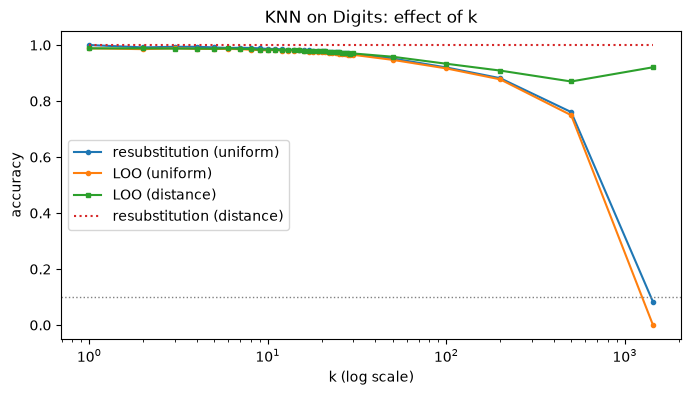

uniform         distance        
       resub     loo    resub     loo
k                                    
1     1.0000  0.9882      1.0  0.9882
3     0.9937  0.9882      1.0  0.9875
5     0.9916  0.9861      1.0  0.9868
7     0.9903  0.9854      1.0  0.9861
10    0.9861  0.9812      1.0  0.9840
20    0.9770  0.9756      1.0  0.9770
50    0.9520  0.9471      1.0  0.9582
200   0.8817  0.8775      1.0  0.9088
1436  0.0828  0.0000      1.0  0.9207

In [83]:
D_tr = np.sqrt(pairwise_sq_dists(Xtr, Xtr))  # 訓練集對自己的歐氏距離 (1437, 1437)


def loo_curve(
    D: np.ndarray,
    y: np.ndarray,
    ks: list[int],
    weights: Literal["uniform", "distance"] = "uniform",
) -> pd.DataFrame:
    """D：訓練集對自己的距離矩陣 (n, n)。

    回傳 DataFrame：index = k，欄位 resub（含自己）與 loo（排除自己）的 accuracy。
    """
    model = KNNClassifier(weights=weights).fit(
        np.zeros((len(y), 1)), y
    )  # 只用到 y；距離由 D 提供
    D_loo = D.copy()
    # TODO 9（程式）：排除自己（一行）
    #   - D_loo[i, i] 是第 i 筆到「自己」的距離 = 0 → 不處理的話，每一筆的最近鄰都是自己（= resubstitution）
    #   - LOO：預測第 i 筆時不能用到它自己 → 把對角線（每一筆到自己的距離）改成一個永遠不會被選進前 k 名的值
    #   - 只改 D_loo（複本），D 保持原樣給 resubstitution 用；提示：第 1 節 EDA 用過同一個函數
    np.fill_diagonal(D_loo, np.inf)
    kmax = max(ks)
    d_in, i_in = model.kneighbors_from_dists(
        D, kmax
    )  # 依距離排序 → 前 k 個就是 k 個最近鄰
    d_out, i_out = model.kneighbors_from_dists(D_loo, kmax)
    rows = []
    for k in ks:
        acc_in = (
            model.classes_[
                model.proba_from_neighbors(d_in[:, :k], i_in[:, :k]).argmax(1)
            ]
            == y
        ).mean()
        acc_out = (
            model.classes_[
                model.proba_from_neighbors(d_out[:, :k], i_out[:, :k]).argmax(1)
            ]
            == y
        ).mean()
        rows.append({"k": k, "resub": acc_in, "loo": acc_out})
    return pd.DataFrame(rows).set_index("k")


ks = list(range(1, 31)) + [50, 100, 200, 500, len(ytr) - 1]
curve_u = loo_curve(D_tr, ytr, ks, "uniform")
curve_d = loo_curve(D_tr, ytr, ks, "distance")

print(
    "✅ LOO 1-NN accuracy：",
    round(curve_u.loc[1, "loo"], 4),
    "（應與第 1 節 ratio < 1 的比例相同）",
)
print("✅ resubstitution 1-NN accuracy：", curve_u.loc[1, "resub"], "（應 = 1.0）")

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(curve_u.index, curve_u["resub"], "o-", ms=3, label="resubstitution (uniform)")
ax.plot(curve_u.index, curve_u["loo"], "o-", ms=3, label="LOO (uniform)")
ax.plot(curve_d.index, curve_d["loo"], "s-", ms=3, label="LOO (distance)")
ax.plot(curve_d.index, curve_d["resub"], ":", label="resubstitution (distance)")
ax.axhline(0.1, color="gray", ls=":", lw=1)
ax.set_xscale("log")
ax.set_xlabel("k (log scale)")
ax.set_ylabel("accuracy")
ax.set_title("KNN on Digits: effect of k")
ax.legend()
plt.show()
display(
    pd.concat({"uniform": curve_u, "distance": curve_d}, axis=1)
    .loc[[1, 3, 5, 7, 10, 20, 50, 200, 1436]]
    .round(4)
)

### TODO 10（問答）

> **(1)** resubstitution 在 $k = 1$ 時一定是 1.0，為什麼？距離加權（distance）的 resubstitution 為什麼「每個 $k$」都是 1.0？這說明在訓練集上評估 KNN 有什麼問題？

- $k = 1$：在訓練集上評估時，查詢點自己就在訓練資料裡，距離 0，一定是自己的最近鄰 → 1-NN 抄自己的標籤，必然 1.0。（前提是沒有「特徵完全相同、標籤不同」的重複樣本；這份資料沒有重複列。）
- distance 加權：自己的距離為 0，觸發 TODO 6 的規則「有距離 0 的鄰居時，只有它們投票」→ 不論 $k$ 多大，都只有自己 1 票，其他鄰居 0 票 → 每個 $k$ 都是 1.0。
- uniform、$k > 1$ 時自己仍佔 $k$ 票中的 1 票，所以 resub 一直比 LOO 高（$k = 3$：0.9937 vs 0.9882）。

**問題**：resubstitution 衡量的是「記住訓練資料」的能力，KNN 把資料原封不動存下來，當然記得 → 分數與推廣能力無關，$k = 1$ 與 distance 加權時甚至完全沒有資訊量（永遠 1.0）。評估 KNN 一定要用 LOO 或 CV；第 5 節學習曲線的 train 線永遠是 1.0，也是同一個原因。

> **(2)** 用偏差—變異（bias–variance）解釋 $k$ 很小與 $k$ 很大時的 LOO 表現。注意：KNN 的「模型複雜度」跟 $k$ 是反方向的 —— 哪一端是複雜模型？

**修正**：這裡的「模型複雜度」不是計算量，而是模型的彈性／容量 —— 決策邊界能彎曲、貼合資料到什麼程度。計算量其實幾乎與 $k$ 無關：predict 的成本由 $n_\text{test} \times n_\text{train} \times d$ 的距離矩陣主導，選前 $k$ 個只多一點點。

| | $k$ 小 = 複雜模型 | $k$ 大 = 簡單模型 |
| --- | --- | --- |
| 預測方式 | 只看極少數鄰居，邊界跟著個別訓練點走（$k = 1$ 時是訓練點的 Voronoi 分割），可以非常彎曲 | 對很多鄰居取多數決，邊界被平滑化 |
| 偏差 | 低：能貼合任何形狀的類別 | 高：鄰域延伸到「自己這一類」的範圍之外，納入越來越多其他類的點，在類別邊界附近、或樣本較少的類別上被多數類淹沒；極端 $k = n$ 時預測變成常數（見 (3)） |
| 變異 | 高：一個標錯或寫得怪的訓練點，就在它周圍劃出一小塊錯誤區域；換一批訓練資料，邊界就大幅改變 | 低 |

（直覺：KNN 的「有效參數數量」約 $n / k$ —— 每 $k$ 個點決定一個局部的預測。）

本例：LOO 在 $k = 1$–3 最好（0.9882），之後單調下降（$k = 10$：0.9812、$k = 50$：0.9471、$k = 200$：0.8775）；resub − LOO 的差距在 $k$ 小時最大、$k$ 大時縮小，與「$k$ 小變異大」一致。Digits 的最佳 $k$ 很小，是因為資料雜訊低、同類樣本很密（第 1 節：98.8% 的最近鄰同類），$k = 1$ 的變異代價很小；雜訊較多的資料，最佳 $k$ 通常會大一些。

> **(3)** $k = n - 1 = 1436$ 時，每一筆的鄰居就是「其他所有訓練資料」—— uniform KNN 退化成哪一種不看 $x$ 的模型？一般 CV 下這種模型的 accuracy 約 0.10，為什麼這裡的 LOO 是 0？（提示：排除自己之後，「自己這一類」剩下幾票？）distance 加權在 $k$ 很大時為什麼退化得比較慢？

（題意：$k = 1436$ 時，每一筆的「鄰居」就是除了自己以外的全部訓練資料，跟它長什麼樣子無關。）

- **退化成 Dummy most_frequent**：uniform 投票 = 數每一類在「其他所有資料」中有幾筆，選最多的類 → 完全不看 $x$。
- **LOO = 0**：類別筆數為 0:142、1:146、2:142、3:146、4:145、5:145、6:145、7:143、8:139、9:144，最多的是 1 與 3（各 146）。排除自己之後，自己這一類永遠少 1 票：
  - 類別 1 的樣本：1 剩 145 票、3 有 146 票 → 預測 3，錯；類別 3 的樣本同理 → 預測 1，錯；
  - 其他類的樣本：自己最多 144 票，輸給 1、3 的 146 票 → 錯。
  - → 每一筆都錯，accuracy = 0。LOO 每次拿掉的那一筆，剛好讓「它自己的類別」吃虧，造成與答案完全負相關的預測；一般 5-fold CV 每個 fold 拿掉的樣本各類都有，多數類不受影響，所以約 0.10。（這是 LOO 對 Dummy 類模型的已知怪現象：LOO 不一定比 $k$-fold 更「公正」。）
- **distance 加權在 $k = 1436$ 仍有 0.9207**：雖然所有點都投票，但票數 $= 1/\text{距離}$，近的同類點（距離約 15–20）票數是遠處點（距離約 50）的好幾倍，加總後仍由附近的點主導 → 模型仍保有「局部」資訊，不會退化成常數。$k$ 變大只是多加進很多「小票」，所以退化得慢。

> **(4)** 對 KNN 做 LOO 只要一個距離矩陣；對邏輯回歸做 LOO 為什麼貴很多？

**修正**：LOO 沒有「抽樣」—— 它是確定性的，每一筆輪流當驗證集，剛好 $n$ 次。

- 邏輯回歸：參數 $w, b$ 是用「全部」訓練資料最佳化出來的，拿掉第 $i$ 筆後最佳解會改變 → 必須重新訓練 $n$ 次，每次 $O(\text{迭代次數} \cdot n \cdot d)$，合計 $O(n^2 \cdot d \cdot \text{迭代次數})$。
- KNN：沒有訓練。拿掉第 $i$ 筆對其他點之間的距離毫無影響，唯一的差別是「第 $i$ 筆不能當自己的鄰居」→ 算一次 $O(n^2 d)$ 的距離矩陣、把對角線設成 $\infty$，就同時得到全部 $n$ 個 LOO 預測，不需要任何重算。
- **本質：LOO 便宜與否，取決於模型能不能便宜地「忘掉」一筆資料。**（延伸：線性回歸／Ridge 也有閉式的 LOO 捷徑，殘差 $e_i / (1 - h_{ii})$，$h_{ii}$ 是 hat matrix 的對角線 —— 見待補強。）

,raw,standard,minmax
k,,,
1,0.9882,0.9743,0.9875
3,0.9882,0.9736,0.9882
5,0.9861,0.9791,0.9868
7,0.9854,0.9770,0.9833
10,0.9812,0.9722,0.9798


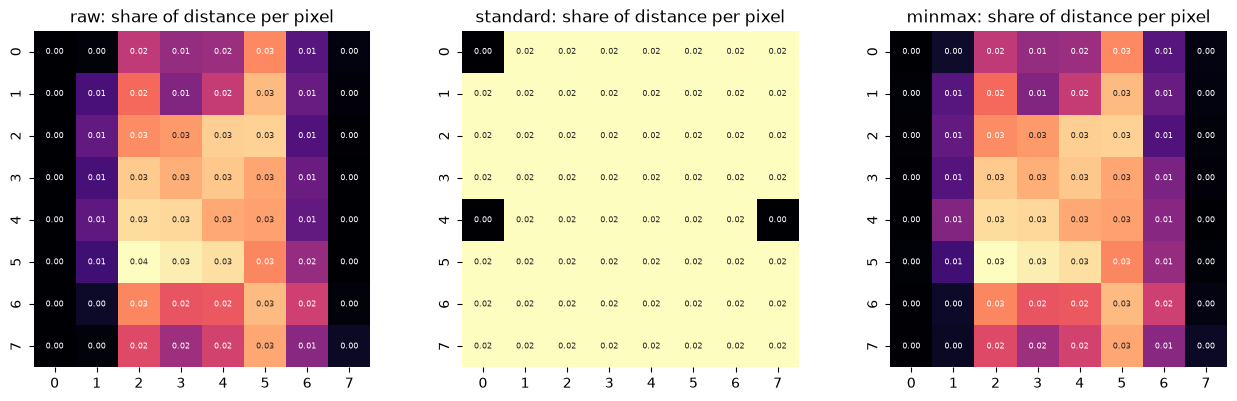

Breast Cancer 的 LOO accuracy：


,raw,standard
k,,
1,0.9143,0.9495
3,0.9319,0.9648
5,0.9429,0.9648
7,0.9363,0.9692
10,0.9341,0.9692


In [85]:
# 實驗 2：尺度。raw vs StandardScaler vs MinMaxScaler（scaler 只用訓練集 fit）
from sklearn.preprocessing import MinMaxScaler, StandardScaler

scalings = {
    "raw": Xtr,
    "standard": StandardScaler().fit_transform(Xtr),
    "minmax": MinMaxScaler().fit_transform(Xtr),
}
ks_small = [1, 3, 5, 7, 10]
scale_tbl = pd.DataFrame(
    {
        name: loo_curve(np.sqrt(pairwise_sq_dists(Xs, Xs)), ytr, ks_small)["loo"]
        for name, Xs in scalings.items()
    }
).round(4)
display(scale_tbl)

# 標準化後，每個像素對平方距離的平均貢獻：E[(x_i − x_j)²] = 2·Var(x)
contrib = pd.DataFrame(
    {name: (2 * Xs.var(axis=0)).reshape(-1) for name, Xs in scalings.items()},
    index=X_train.columns,
)
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, name in zip(axes, scalings):
    share = contrib[name] / contrib[name].sum()
    sns.heatmap(
        share.to_numpy().reshape(8, 8),
        cmap="magma",
        ax=ax,
        square=True,
        cbar=False,
        annot=True,
        fmt=".2f",
        annot_kws={"size": 6},
    )
    ax.set_title(f"{name}: share of distance per pixel")
fig.tight_layout()
plt.show()

# 對照：第三章的 Breast Cancer（30 個特徵，尺度差 10⁵ 倍）
from ml_dl_llm.data import load_breast_cancer

Xb_tr, _, yb_tr, _ = load_breast_cancer()
Xb = Xb_tr.to_numpy()
bc = pd.DataFrame(
    {
        "raw": loo_curve(
            np.sqrt(pairwise_sq_dists(Xb, Xb)), yb_tr.to_numpy(), ks_small
        )["loo"],
        "standard": loo_curve(
            np.sqrt(pairwise_sq_dists(*(2 * [StandardScaler().fit_transform(Xb)]))),
            yb_tr.to_numpy(),
            ks_small,
        )["loo"],
    }
).round(4)
print("Breast Cancer 的 LOO accuracy：")
display(bc)

### TODO 11（問答）

> **(1)** Digits 上標準化讓 KNN 變差、Breast Cancer 上標準化讓 KNN 變好很多。用上面「每個像素佔距離的比例」三張圖解釋：standard 之後，哪些像素的份量被放大？它們攜帶的是「字形資訊」還是「雜訊」？（提示：一個 99% 時間是 0、偶爾是 1 的像素，標準化後偶爾出現的值變成多少個標準差？）

被放大的是圖片邊緣（最左、最右兩欄）的低變異像素，它們攜帶的主要是**雜訊**（偶爾出現的筆畫邊角、偏移），不是字形資訊。

| | 每個像素的份量 | 9 個「低變異但不恆為 0」的邊緣像素合計 |
| --- | --- | --- |
| raw | $\propto$ 變異：邊緣 ≈ 0.00、中央約 0.03 | 0.03% —— 距離幾乎完全由中央的筆畫決定 |
| standard | 全部拉成一樣：$1/61 \approx 0.016$（3 個恆為 0 的像素仍是 0） | 14.8%，放大約 500 倍 |

提示的算法：一個像素以機率 $p$ 為 1、其餘為 0，平均 $p$、標準差 $\sqrt{p(1-p)}$，值 1 標準化後

$$z = \frac{1-p}{\sqrt{p(1-p)}} \approx \frac{1}{\sqrt{p}}$$

$p = 1\%$ → 約 10 個標準差；$p = 0.1\%$ → 約 32 個。實測 pixel_7_0 的 1 變成 37.9，單一像素貢獻 $37.9^2 \approx 1{,}400$ 的平方距離，比典型最近鄰的整段平方距離（約 270）還大 → 一個邊緣雜點就決定了誰是鄰居。

- minmax 幾乎跟 raw 一樣：多數像素範圍都是 0–16，除以 16 等於整體縮放，不改變相對份量；只有範圍很小的邊緣像素（最大值 1–2）被相對放大，所以略差一點點。
- Breast Cancer 正好相反：raw 距離的 99% 來自 worst area（71%）與 mean area（28%），KNN 實際上只用面積在判斷；標準化讓其他 28 個特徵也能參與，LOO 從 0.91–0.94 升到 0.95–0.97。

> **(2)** 由此整理一個原則：KNN 什麼時候「必須」標準化、什麼時候「不該」標準化？跟第三章邏輯回歸（梯度下降、L2）需要標準化的理由，是同一個理由嗎？

**原則**：對 KNN 而言，縮放 = 決定每個特徵在距離中的權重（份量 $\propto$ 縮放後的變異），所以問題是「原始變異大小有沒有意義」：

| 情況 | 做法 | 例子 |
| --- | --- | --- |
| 特徵的單位／量級不同，變異大小只反映單位、不反映重要性 | **必須**標準化，否則距離被大單位的特徵壟斷 | Breast Cancer：面積 $\sim 10^3$ vs 比值 $\sim 0.1$ |
| 特徵單位相同、變異大小本身就代表資訊量；尤其有「幾乎恆定、偶爾跳一下」的特徵 | **不該**標準化（會把雜訊放大成主角）；若仍想標準化，先刪掉近乎零變異的特徵（`VarianceThreshold`） | 像素、同一種感測器的讀數 |
| 不確定 | 把 scaler 當超參數，用 CV 比較 | 第 5 節的 GridSearch |

**與第三章：不是同一個理由。**

- 第三章：標準化是為了「最佳化」與「正則化」。
  - 梯度下降：尺度差異造成 Hessian 條件數極大，學習率被最陡方向限制、平緩方向幾乎不動 → 收斂極慢（影響速度）。
  - L2：同一個 $\lambda$ 對不同尺度的係數罰得不公平 → 會改變解。
  - 不加正則化時，邏輯回歸對縮放是「等價」的：特徵乘 $c$，係數自動除以 $c$，預測完全相同。
- KNN：沒有最佳化也沒有係數可以調整來抵銷縮放，縮放直接改變距離 → 直接改變誰是鄰居、改變預測。它不是「數值好不好算」的問題，而是「模型本身是什麼」的問題（等於選了一個不同的距離）。

**修正**：「大數值的變數主導梯度方向」是條件數問題的一種描述，但結論應是「收斂慢」而非「解不同」；KNN 這邊的精確說法是「低變異的雜訊像素被賦予與筆畫像素相同的權重」，而不是「類別變得不易偵測」。

,L1,L2,cosine
k,,,
1,0.9833,0.9882,0.9868
3,0.9833,0.9882,0.9868
5,0.9826,0.9861,0.9875
7,0.9833,0.9854,0.9861
10,0.9791,0.9812,0.9812


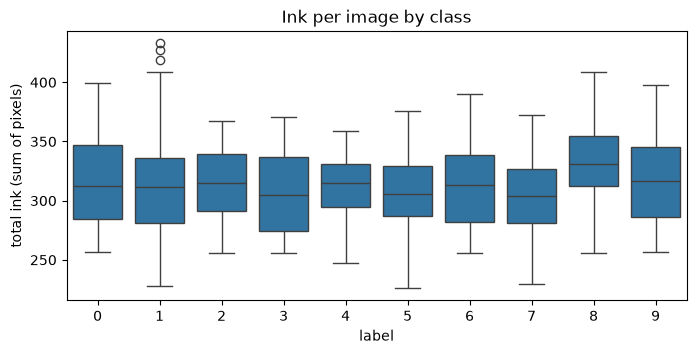

In [87]:
# 實驗 3：距離的種類。L1（曼哈頓）、L2（歐氏）、cosine（只看方向，不看長度）
metrics_tbl = pd.DataFrame(
    {
        m: loo_curve(cdist(Xtr, Xtr, m), ytr, ks_small)["loo"]
        for m in ["cityblock", "euclidean", "cosine"]
    }
).round(4)
metrics_tbl.columns = ["L1", "L2", "cosine"]
display(metrics_tbl)

# 每張影像的「墨水量」（像素總和）在各類中的分布：cosine 會忽略這個資訊
ink = train.drop(columns="label").sum(axis=1)
fig, ax = plt.subplots(figsize=(8, 3.5))
sns.boxplot(x=train["label"], y=ink, ax=ax)
ax.set_ylabel("total ink (sum of pixels)")
ax.set_title("Ink per image by class")
plt.show()

In [88]:
# 實驗 4：維度詛咒（curse of dimensionality）
# (a) 均勻分布的隨機點：維度變高時，「最近」和「最遠」的距離差多少？
rng = np.random.default_rng(42)
rows = []
for d in [2, 8, 64, 256, 1024]:
    P = rng.uniform(size=(1000, d))
    Dq = np.sqrt(pairwise_sq_dists(P[:50], P[50:]))  # 50 個查詢點對 950 個點
    rows.append(
        {
            "d": d,
            "min": Dq.min(1).mean(),
            "max": Dq.max(1).mean(),
            "(max − min) / min": ((Dq.max(1) - Dq.min(1)) / Dq.min(1)).mean(),
        }
    )
display(pd.DataFrame(rows).round(3))

# (b) 在 Digits 加入 m 個純雜訊特徵（均勻 0–16，跟標籤無關），1-NN 與 5-NN 的 LOO accuracy
rows = []
for m in [0, 8, 32, 128, 512]:
    Xn = np.c_[Xtr, rng.uniform(0, 16, size=(len(Xtr), m))]
    c = loo_curve(np.sqrt(pairwise_sq_dists(Xn, Xn)), ytr, [1, 5])["loo"]
    rows.append({"noise features": m, "LOO 1-NN": c[1], "LOO 5-NN": c[5]})
display(pd.DataFrame(rows).round(4))

,d,min,max,(max − min) / min
0,2,0.015,1.023,93.469
1,8,0.376,1.761,3.827
2,64,2.499,3.950,0.582
3,256,5.789,7.216,0.247
4,1024,12.325,13.771,0.117


,noise features,LOO 1-NN,LOO 5-NN
0,0,0.9882,0.9861
1,8,0.9840,0.9847
2,32,0.9603,0.9812
3,128,0.8880,0.9228
4,512,0.6701,0.7850


### TODO 12（問答）

> **(1)** (a) 的表格：維度變高時，$(\max - \min)/\min$ 怎麼變？這對「最近鄰」這個概念有什麼影響？（提示：如果所有點離你都差不多遠，「最近的 5 個」還有意義嗎？）

$(\max - \min)/\min$ 衡量「最遠的點比最近的點遠多少倍」（相對對比，relative contrast）：

| $d$ | 最近 | 最遠 | $(\max-\min)/\min$ | 直覺 |
| --- | --- | --- | --- | --- |
| 2 | 0.015 | 1.02 | 93 | 最近的點幾乎貼著你，「近」和「遠」差別極大 |
| 64 | 2.50 | 3.95 | 0.58 | 最遠的只比最近的遠 58% |
| 1024 | 12.3 | 13.8 | 0.12 | 所有點離你幾乎一樣遠 |

**原因（距離集中，concentration of distances）**：平方距離是 $d$ 個獨立項的總和，總和的平均 $\propto d$，波動（標準差）只 $\propto \sqrt{d}$ → 相對波動 $\propto 1/\sqrt{d}$ → 維度越高，所有距離越擠在平均值附近。（跟「擲 1000 次硬幣，正面比例幾乎一定接近 50%」是同一個大數法則。）

**對最近鄰的影響**：KNN 的前提是「近的點比較像我」。當最近與最遠只差 12%，「最近的 5 個」跟隨便挑 5 個差不多，排名主要由隨機波動決定，不再反映相似度 → 最近鄰失去意義。這就是**維度詛咒**（curse of dimensionality）對 KNN 的核心打擊。

注意：這是「均勻、各維度獨立」的隨機點；真實資料不一定這樣，見 (3)。

> **(2)** (b) 加了 512 個雜訊特徵，accuracy 掉了多少？用「每個特徵對平方距離的貢獻是相加的」解釋：有用的 64 維訊號和 512 維雜訊，誰主導了距離？（對照：邏輯回歸遇到無關特徵時，可以把它的係數學成接近 0；KNN 可以嗎？）

1-NN：0.9882 → 0.6701（掉 32 個百分點）；5-NN：0.9861 → 0.7850（掉 20 個百分點）。

平方距離 = 訊號部分（64 個像素）＋ 雜訊部分（512 個雜訊特徵），兩部分直接相加：

- 訊號：最近同類的平方距離中位數 270、最近異類 899 → 能分辨類別的「差距」約 **600**。
- 雜訊：每個均勻 0–16 的特徵平均貢獻 $2\,\mathrm{Var} = 2 \cdot 16^2/12 \approx 43$，512 個 → 平均約 21,900；而且這個值每一對點都不同，標準差約 **1,150**（實測）。
- 雜訊的「波動」（±1,150）比訊號的「差距」（約 600）還大 → 誰是最近鄰主要由雜訊決定，同類鄰居被隨機的異類點擠掉。雜訊的平均值本身不是問題（對每一對都差不多，只是整體平移），問題是它的隨機波動蓋過了訊號。
- 5-NN 掉得較少：多數決平均掉一部分隨機性（變異較小），但擋不住。

與邏輯回歸對照：

- 邏輯回歸有可學習的係數，無關特徵的係數會被學成接近 0（加 L1 甚至恰為 0），等於自動忽略它。
- KNN 沒有參數：歐氏距離把每個特徵「一視同仁」地相加，無法從資料學到「這個特徵沒用」。它對無關特徵非常脆弱 → KNN 之前常需要特徵選擇、降維（PCA）或學一個距離（metric learning，見待補強）。

**修正**：不是「維度增加，距離一定增加」本身造成問題 —— 所有距離一起變大不會改變排名；改變排名的是雜訊項在不同配對之間的差異。

> **(3)** Digits 是 64 維，KNN 卻表現很好、沒有被維度詛咒打敗。為什麼？（提示：PCA 2 維就解釋了多少變異？真實影像在 64 維空間裡是「均勻散開」的嗎？intrinsic dimension）

因為 Digits 雖然「寫成」64 個數字，實際上只在一個低維的結構上變化（**intrinsic dimension 遠低於 64**）：像素之間高度相關，相鄰像素一起亮一起暗，一個筆畫同時決定好幾十個像素；手寫數字的變化來源其實不多（哪個數字、粗細、傾斜、位置、幾種寫法）。

| 證據 | Digits | 64 維均勻隨機點 |
| --- | --- | --- |
| PCA 前 2 個主成分解釋的變異 | 28.5% | 4.5% |
| 達到 90% 需要幾個主成分 | 21（13 個 80%） | 55 |
| $(\max - \min)/\min$（同 (a) 的算法） | 3.30（最近 16.3、最遠 65.8），跟均勻資料的 $d = 8$（3.83）差不多 | 0.58 |
| 最近鄰距離中位數 vs 任兩點距離中位數（第 1 節） | 16.4 vs 49 → 鄰居明顯比一般點近 | — |

**結論**：維度詛咒看的是資料「實際佔據」的維度（intrinsic dimension），不是欄位數（ambient dimension）。真實資料（影像、聲音、文字）通常落在高維空間中一個低維的「流形」（manifold）附近 —— 這也是 PCA、t-SNE、UMAP（第 14、15 章）與深度學習表徵能運作的前提（manifold hypothesis）。(b) 加入的雜訊則是真正「各自獨立、均勻散開」的維度，每加一維就真的提高 intrinsic dimension，所以傷害很大。

---
## 4. 套件實作：sklearn `KNeighborsClassifier`

依 3C 的結果，Digits 不做標準化；但為了讓「要不要標準化」也能當成超參數搜尋（第 5 節），
`Pipeline` 第一步保留一個 `scaler` 位置，預設 `"passthrough"`（什麼都不做）。

In [90]:
from sklearn.pipeline import Pipeline

knn_pipe = Pipeline(
    [("scaler", "passthrough"), ("knn", KNeighborsClassifier(n_neighbors=5))]
)
knn_pipe.fit(X_train, y_train)

scratch = KNNClassifier(k=5).fit(Xtr, ytr)
print(
    "✅ 手寫 vs sklearn predict 一致比例：",
    (scratch.predict(Xte) == knn_pipe.predict(X_test)).mean(),
    "（應 = 1.0）",
)
print(
    "✅ predict_proba 最大差異：",
    np.abs(scratch.predict_proba(Xte) - knn_pipe.predict_proba(X_test)).max(),
    "（應 < 1e-6）",
)
print("sklearn 實際用的搜尋演算法：", knn_pipe[-1]._fit_method)

✅ 手寫 vs sklearn predict 一致比例： 1.0 （應 = 1.0）
✅ predict_proba 最大差異： 0.0 （應 < 1e-6）
sklearn 實際用的搜尋演算法： brute


In [91]:
# 搜尋演算法：brute（全部算一遍）vs KD-Tree vs Ball Tree —— 結果一樣，速度不同
from collections.abc import Callable


def timing(
    X_fit: np.ndarray,
    y_fit: np.ndarray,
    X_query: np.ndarray,
    algorithm: str,
    repeat: int = 2,
) -> tuple[float, float, np.ndarray]:
    """回傳 (fit 秒數, 查詢秒數（repeat 次取最快）, 鄰居編號 (n_query, 5))。"""
    m = KNeighborsClassifier(n_neighbors=5, algorithm=algorithm)
    t0 = time.perf_counter()
    m.fit(X_fit, y_fit)
    t_fit = time.perf_counter() - t0
    t_pred = min(_timeit(lambda: m.kneighbors(X_query)) for _ in range(repeat))
    return t_fit, t_pred, m.kneighbors(X_query, return_distance=False)


def _timeit(f: Callable[[], object]) -> float:
    """執行 f 一次，回傳花費的秒數。"""
    t0 = time.perf_counter()
    f()
    return time.perf_counter() - t0


rng = np.random.default_rng(0)
rows = []
for name, d in [("synthetic d=2", 2), ("synthetic d=8", 8), ("synthetic d=64", 64)]:
    P = rng.normal(size=(20000, d))
    Q = rng.normal(size=(1000, d))
    lab = rng.integers(0, 10, 20000)
    ref = None
    for alg in ["brute", "kd_tree", "ball_tree"]:
        t_fit, t_pred, nb = timing(P, lab, Q, alg)
        ref = nb if ref is None else ref
        rows.append(
            {
                "data": name,
                "algorithm": alg,
                "fit ms": t_fit * 1e3,
                "query ms": t_pred * 1e3,
                "same neighbours as brute": (nb == ref).mean(),
            }
        )
display(pd.DataFrame(rows).round(2))

,data,algorithm,fit ms,query ms,same neighbours as brute
0,synthetic d=2,brute,1.61,11.19,1.0
1,synthetic d=2,kd_tree,5.04,1.56,1.0
2,synthetic d=2,ball_tree,4.89,10.33,1.0
3,synthetic d=8,brute,1.19,8.61,1.0
4,synthetic d=8,kd_tree,7.26,33.75,1.0
5,synthetic d=8,ball_tree,6.97,83.42,1.0
6,synthetic d=64,brute,1.49,14.11,1.0
7,synthetic d=64,kd_tree,20.29,850.56,1.0
8,synthetic d=64,ball_tree,22.39,594.90,1.0


### TODO 13（問答）

> **(1)** $d = 2$ 時 KD-Tree 比 brute 快很多；維度一高，優勢很快消失、甚至慢上許多倍。為什麼？

> **(a)** 讀表格：$d$ = 2、8、64 時，kd_tree 的 query 時間各是 brute 的幾倍？從哪個 $d$ 開始 kd_tree 比 brute 慢？

| $d$ | kd_tree ÷ brute | |
| --- | --- | --- |
| 2 | 1.40 / 11.57 = 0.12 | 快約 8 倍 |
| 8 | 32.9 / 9.5 = 3.5 | 慢 |
| 64 | 882 / 12.8 = 69 | 慢很多 |

從 $d = 8$ 就開始比 brute 慢。ball_tree 也一樣：$d = 64$ 慢 46 倍。時間每台電腦不同，但趨勢一致。

**修正**：原本寫的 0.29、0.01 是 brute ÷ kd_tree，方向顛倒了；比值 > 1 才是 kd_tree 比較慢。

> **(b)** KD-Tree 的原理：沿某一軸切一刀把點分成兩半，再對每一半遞迴地切，最後空間被切成很多小盒子。查詢時先走到查詢點所在的盒子，在裡面找到「目前第 $k$ 近的距離 $r$」；之後任何盒子，只要它離查詢點「最近可能的距離」已經 $> r$，整個盒子就跳過不看。→ 能跳過多少盒子，取決於 $r$ 和「查詢點到其他盒子的距離」誰大？

$r$ 越小於「到其他盒子的距離」，能跳過的盒子越多：

- $r$ 很小（最近鄰就在身邊）、其他盒子都在 $r$ 之外 → 幾乎整棵樹都被跳過，只看附近幾個盒子 → 快；
- $r$ 跟到大多數盒子的距離差不多 → 跳不掉，最後還是得一個個盒子打開來算 → 跟 brute 一樣多的計算，再加上走樹的成本。

> **(c)** 回到 TODO 12 (1)：$d$ 高時，最近點的距離 $r$ 跟一般點的距離差不多。這時以 $r$ 為半徑的球，會碰到少數幾個盒子，還是幾乎所有盒子？還能跳過多少？

幾乎所有盒子都會和以 $r$ 為半徑的球相交 → 幾乎跳不掉。（「半球」→ 球。）$d = 64$ 的均勻資料：最近 2.5、最遠 3.95，$r$ 已經是「到大多數點的距離」的 60% 以上。

> **(d)** 另一個角度：20,000 個點，每切一刀點數減半，約切 $\log_2 20000 \approx 14$ 刀就到底了。$d = 2$ 時每一軸能被切約 7 次；$d = 64$ 時呢？大部分的軸根本沒被切到，盒子在那些軸上有多「寬」？

樹的深度（從根到葉要切幾刀）只有約 $\log_2 n$ 層，跟 $d$ 無關。（sklearn 的葉子預設最多 30–40 個點，實際深度約 $\log_2(20000/30) \approx 9$–10 層。）

- $d = 2$：約 10 刀分給 2 個軸，每軸被切約 5 次 → 每個盒子在兩個方向都很窄。
- $d = 64$：從根走到任何一片葉子，最多只切過約 10 個軸 → 其餘 50 多個軸「一刀都沒切」，盒子在那些軸上跟整份資料一樣寬（從最小值到最大值）。

**後果**：「查詢點到盒子的最近可能距離」只能從被切過的那約 10 個軸算出來（其他軸上查詢點一定落在盒子範圍內，貢獻 0），但真正的 $r$ 是 64 個軸累加起來的 → 下界遠小於 $r$，幾乎每個盒子都「可能」藏著更近的點，無法排除。→ 維度一高，盒子在大部分方向上都是「全寬」的，空間切割本身就失去意義。

> **(e)** brute 不做任何跳過，為什麼在高維反而贏？

| | brute | 樹（跳不掉時） |
| --- | --- | --- |
| 計算量 | 全部距離 | 跟 brute 差不多 |
| 做法 | 一整批查詢 = 一次矩陣乘法（TODO 3 的 `A @ B.T`），呼叫 BLAS：SIMD 向量指令、快取分塊、多執行緒 | 每個節點一次分支判斷、維護「目前前 $k$ 名」的堆積（heap）與待查節點，一個查詢點一個查詢點處理 |
| 記憶體存取 | 依序讀取，CPU 幾乎滿載在做乘加 | 跳來跳去，快取命中率差 |

→ 同樣的計算量，「一次大矩陣乘法」遠比「很多次小計算 + 大量判斷」快；跳不掉時，樹只剩額外開銷。sklearn 的 `algorithm="auto"` 也會依 $d$、$n$、$k$ 自動判斷，這份 Digits 選的就是 brute（上一格的輸出）。

> **(2)** 樹狀結構把成本從 predict 移了一部分到 fit。

> **(a)** 讀表格的 fit 欄：brute 的 fit 幾乎不花時間（只存資料）；kd_tree、ball_tree 的 fit 花在做什麼？

建樹：遞迴地選切分的軸（通常是分布最寬的軸）、找中位數把點分兩半（$O(n)$ 的 partition），每層 $O(n)$、共 $O(\log n)$ 層 → $O(n \log n)$；ball_tree 另外要算每個節點的球心與半徑。$d$ 越大，每層要比較的資料越多，所以 $d = 64$ 的 fit 也最慢。

> **(b)** 算一筆帳：假設建樹多花 100 ms、每次查詢省 1 ms，查詢幾次後回本？「訓練一次、查詢上百萬次」的應用（例如以圖搜圖），這是好交易嗎？

100 次回本。查詢上百萬次時，100 ms 的建樹成本平均到每次查詢只剩 0.0001 ms，可以忽略 → 非常好的交易；而且建樹可以在服務上線前（離線）做好，使用者只感受到查詢速度。

但前提是「每次查詢真的省時間」：這張表 $d$ = 8、64 時 kd_tree 每次查詢反而更慢，多花的 fit 永遠回不了本。所以是低維才划算；高維就要換 (c) 的方法。

> **(c)** 當 $n$ 到億級、$d$ 到數百維：KD-Tree 因為 (1) 失效，brute 每次查詢要算一億個距離又太慢。如果允許「偶爾找到的不是真正最近的，而是第 2、3 近的」，可以換來什麼？這類方法叫什麼？

**近似最近鄰（Approximate Nearest Neighbor，ANN）。**

- 放棄：精確性 —— 找到的前 $k$ 名不保證全對，用 recall@k（例如真正的前 10 名找回 95–99%）衡量。
- 換到：查詢速度快好幾個數量級（不必和每一個點算距離，查詢成本遠低於 $O(n)$），常常還能壓縮向量、省下大量記憶體。
- 代表方法：HNSW（在點之間建「鄰居圖」，沿著圖往查詢點走）、IVF（先分群，只搜最接近的幾群）、PQ（把向量壓縮成短碼）、LSH（雜湊讓相近的點落在同一桶）；FAISS 是實作這些方法的函式庫。
- 第四章 RAG 的向量資料庫就是靠 ANN 在數百萬個 embedding 中即時找最相近的文件。

---
## 5. 調參

全程只用 `X_train`（測試集鎖住），依 README「調參流程」：

| 類別 | 超參數 | 說明 |
| --- | --- | --- |
| 容量 | `n_neighbors`（k） | k 小 = 邊界彎曲、模型複雜；k 大 = 邊界平滑、模型簡單 |
| 投票方式 | `weights` | `"uniform"` 或 `"distance"` |
| 距離 | `p`／`metric` | p = 1 曼哈頓、p = 2 歐氏（實驗 3） |
| 前處理 | `scaler` | `"passthrough"`、`StandardScaler()`：前處理也可以當超參數搜尋（實驗 2） |
| 速度 | `algorithm`、`leaf_size` | 只影響速度、不影響結果，不需要調 |

**選模型的指標用 accuracy**，理由在 TODO 14 (2)。

In [93]:
from sklearn.model_selection import GridSearchCV, learning_curve, validation_curve

baseline.loc["KNN default (k=5)"] = cv_summary(knn_pipe)
baseline.loc["KNN k=1"] = cv_summary(
    Pipeline([("scaler", "passthrough"), ("knn", KNeighborsClassifier(1))])
)
display(baseline)

,accuracy,log_loss
Dummy most_frequent,0.1009 ± 0.0002,32.4067 ± 0.0062
Dummy prior,0.1009 ± 0.0002,2.3025 ± 0.0000
NearestCentroid,0.9081 ± 0.0097,1.5589 ± 0.3542
KNN default (k=5),0.9875 ± 0.0075,0.1843 ± 0.0950
KNN k=1,0.9854 ± 0.0068,0.5269 ± 0.2435


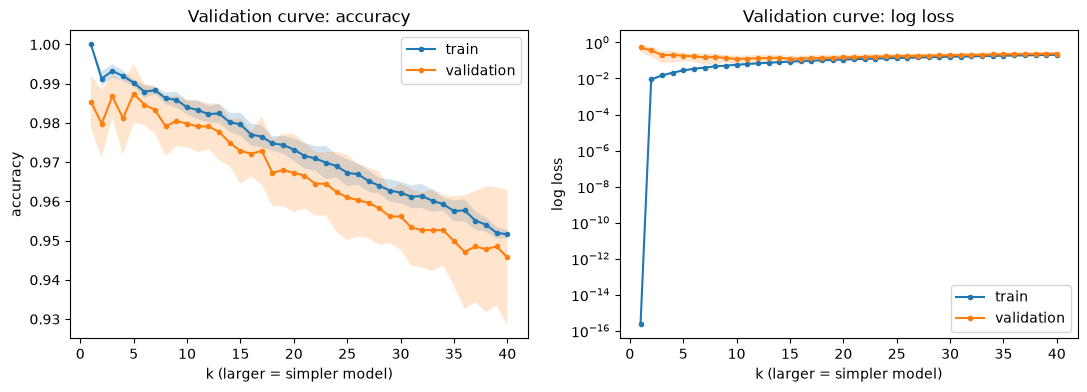

,train_acc,val_acc,val_acc_std,val_log_loss
k,,,,
1,1.0000,0.9854,0.0068,0.5269
2,0.9913,0.9798,0.0086,0.3633
3,0.9932,0.9868,0.0056,0.1981
4,0.9920,0.9812,0.0092,0.2056
5,0.9903,0.9875,0.0075,0.1843
7,0.9883,0.9833,0.0060,0.1496
10,0.9840,0.9798,0.0060,0.1198
15,0.9796,0.9729,0.0084,0.1234
20,0.9732,0.9673,0.0100,0.1473


In [94]:
# 單一參數掃描：k
k_range = np.arange(1, 41)
res_vc = {}
for scoring in ["accuracy", "neg_log_loss"]:
    tr, va = validation_curve(
        knn_pipe,
        X_train,
        y_train,
        param_name="knn__n_neighbors",
        param_range=k_range,
        cv=cv,
        scoring=scoring,
    )
    sign = -1 if scoring == "neg_log_loss" else 1
    res_vc[scoring] = (sign * tr, sign * va)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, scoring, ylabel in [
    (axes[0], "accuracy", "accuracy"),
    (axes[1], "neg_log_loss", "log loss"),
]:
    for name, s in zip(["train", "validation"], res_vc[scoring]):
        ax.plot(k_range, s.mean(1), "o-", ms=3, label=name)
        ax.fill_between(k_range, s.mean(1) - s.std(1), s.mean(1) + s.std(1), alpha=0.2)
    ax.set_xlabel("k (larger = simpler model)")
    ax.set_ylabel(ylabel)
    ax.legend()
axes[1].set_yscale("log")
axes[0].set_title("Validation curve: accuracy")
axes[1].set_title("Validation curve: log loss")
plt.show()

vc_tbl = pd.DataFrame(
    {
        "k": k_range,
        "train_acc": res_vc["accuracy"][0].mean(1),
        "val_acc": res_vc["accuracy"][1].mean(1),
        "val_acc_std": res_vc["accuracy"][1].std(1),
        "val_log_loss": res_vc["neg_log_loss"][1].mean(1),
    }
).set_index("k")
display(vc_tbl.loc[[1, 2, 3, 4, 5, 7, 10, 15, 20, 30, 40]].round(4))

### TODO 14（問答）

> **(1)** 哪一段 $k$ 是過擬合、哪一段是欠擬合？

> **(a)** 讀表格：$k$ = 1、5、40 時，train_acc 與 val_acc 各是多少？兩者的差距（train − val）怎麼隨 $k$ 變化？

| $k$ | train_acc | val_acc | train − val |
| --- | --- | --- | --- |
| 1 | 1.000 | 0.9854 | 0.0146 |
| 5 | 0.9903 | 0.9875 | 0.0028 |
| 40 | 0.9516 | 0.9457 | 0.0059 |

差距：$k = 1$ 最大，$k$ 變大後縮到 0.003–0.006 附近（$k = 40$ 的 0.0059 與 $k = 5$ 的 0.0028 差不到一個 std，可視為「維持很小」，不是真的回升）。更重要的是兩條線的「高度」：$k$ 大時 train、val 一起往下掉。

注意：這裡的 train_acc 是 resubstitution（查詢點自己也在訓練集裡），$k = 1$ 時必然 1.0（TODO 10 (1)）。

> **(b)** 一般判斷：train 很高、val 明顯較低、差距大 → 過擬合；train 和 val 一起變低、差距小 → 欠擬合。套用到 (a)：哪一端是過擬合、哪一端是欠擬合？

**修正：方向相反。**

- 左端（$k$ 小，$k$ = 1–2）＝**過擬合**：train = 1.0，差距最大（0.015）—— 模型把訓練資料背起來了。
- 右端（$k$ 大，$k \gtrsim 15$）＝**欠擬合**：train 和 val 一起下降（$k = 40$：0.95、0.95），差距仍小 —— 模型太粗，連訓練集都學不好。
- 中間 $k \approx 3$–7 是兩者的平衡點。

> **(c)** val_acc 最高在哪個 $k$？$k$ = 1～7 之間的差異，跟 val_acc_std（約 0.006–0.009）比起來大嗎？真的分得出誰最好嗎？

最高在 $k = 5$（0.9875）。$k$ = 1–7 的 val_acc 在 0.9798–0.9875 之間，最大差距 0.008，約等於一個 std → 統計上分不出誰最好（判斷正確）。此時依 1-SE rule 選「最簡單」的模型 —— 而對 KNN，最簡單的是 $k$ 最「大」的那個（見 (d)），不是 $k$ 最小的。

> **(d)** 第三章 C 的 validation curve：C 越大模型越複雜，過擬合在「右邊」。這裡 x 軸是 $k$，複雜的一端在左邊還是右邊？（TODO 10 (2)：$k$ 小 = 邊界跟著個別點走）

**修正：複雜的一端在左邊，$k$ 小 = 複雜。**

「複雜度」不是計算量（$k$ 大時雖然要看比較多點，但計算量幾乎不變，見 TODO 10 (2)），而是「預測對個別訓練點有多敏感」：

- $k = 1$：只聽 1 個鄰居。改掉 1 個訓練點的標籤，它周圍一整塊區域的預測就跟著翻 → 邊界彎彎曲曲、跟著每個點走 → 複雜。
- $k = 40$：聽 40 個鄰居的多數決。改掉 1 個點只動 1/40 的票，預測幾乎不變 → 邊界平滑 → 簡單。
- 類比：問 1 個朋友的意見 vs 問 40 個朋友後投票，前者容易被單一怪意見帶走。

所以這張圖是第三章 C 的「左右鏡像」：第三章 C 大（右）過擬合；這裡 $k$ 小（左）過擬合。

> **(2)** $k = 1$ 的 val log loss 很大（約 0.5），$k$ 變大時 log loss 一路下降，accuracy 卻在 $k \approx 3$–5 之後開始變差。

> **(a)** $k = 1$ 時只有 1 個鄰居投票，`predict_proba` 的每一列長什麼樣（只會出現哪兩種數字）？猜錯時，正確類別的機率是多少？

**修正：不是 0.1、0.9。** 唯一的鄰居拿走全部的票：它的類別機率 = 1，其他 9 類 = 0，例如 `[0, 0, 0, 1, 0, 0, 0, 0, 0, 0]`。只會出現 0 和 1。猜錯時，正確類別一票都沒有 → 正確類別的機率 = 0。

> **(b)** sklearn 把機率 0 裁成 $\varepsilon \approx 2.2\times10^{-16}$，猜錯一筆的 loss $= -\ln\varepsilon \approx 36$；猜對一筆的 loss $= -\ln 1 = 0$。$k = 1$ 的 val accuracy 約 0.985 → 錯誤率約 1.5%。手算平均 log loss，跟表格的值比對。

$$\overline{\text{log loss}} = (\text{猜對的比例}) \times 0 + (\text{猜錯的比例}) \times 36 = 0.9854 \times 0 + 0.0146 \times 36.04 \approx 0.526$$

跟表格的 0.5269 幾乎一樣。→ $k = 1$ 的 log loss 完全是「錯誤率 × 36」，只是把 accuracy 換個尺度而已。

> **(c)** $k = 5$ 時，機率只可能是哪些值？（提示：5 票分給 10 類）猜錯時，「正確類別還拿到 1 票」（機率 0.2）跟「一票都沒有」（機率 0），單筆 loss 各是多少？所以 log loss 隨 $k$ 下降，主要是因為模型「猜得更準」，還是因為機率「不再出現 0」？

$k = 5$：每類的機率 = 票數 / 5，只可能是 0、0.2、0.4、0.6、0.8、1.0（每個鄰居只能投給「自己的標籤」，沒有選擇）。

例：一張真實標籤是 8 的圖，$k = 5$：

| 情況 | 5 個鄰居的標籤 | 預測 | $P(8)$ | 單筆 loss |
| --- | --- | --- | --- | --- |
| A 猜對 | 8, 8, 8, 1, 1 | 8 ✓ | 0.6 | $-\ln 0.6 = 0.51$ |
| B 猜錯，正確類別 1 票 | 1, 1, 1, 1, 8 | 1 ✗ | 0.2 | $-\ln 0.2 = 1.61$ |
| C 猜錯，正確類別 0 票 | 1, 1, 1, 9, 9 | 1 ✗ | 0 | $-\ln\varepsilon = 36$ |

B、C 都是猜錯，loss 卻差 22 倍；$k = 1$ 時所有錯誤都是 C。

**主要是因為「不再出現 0」**。實測（5-fold）：

| $k$ | accuracy | 正確類別 0 票的比例 | log loss | 其中來自 0 票樣本 |
| --- | --- | --- | --- | --- |
| 1 | 0.9854 | 1.46% | 0.527 | 0.527（100%） |
| 5 | 0.9875 | 0.42% | 0.184 | 0.151（82%） |
| 10 | 0.9798 | 0.14% | 0.120 | 0.050（42%） |

$k = 10$ 的 accuracy 比 $k = 5$ 差，log loss 卻好很多 —— 因為票分給更多鄰居，正確類別「至少拿到 1 票」的機會變大，少了幾筆 36 的懲罰。**log loss 主要在量「有多少樣本的正確類別完全沒票」，不是在量「猜得準不準」。**

> **(d)** 如果用 log loss 選 $k$，會被推向哪個 $k$？用 accuracy 呢？這個任務真正在乎的是哪一個？

- log loss 最低在 $k \approx 10$（0.120）；accuracy 最高在 $k$ = 3–5（0.987）。
- 任務是「辨認這張圖是哪個數字」，在乎的是猜對的比例 → **accuracy**。用 log loss 選，會選到一個 accuracy 較差（0.980）的 $k$。
- 若下游真的需要可信的機率，該做的是另外校準，而不是用 log loss 選 $k$，見 (e)。

> **(e)** 對照第三章：邏輯回歸的機率是 $\sigma(w\cdot x + b)$，是連續值，而且訓練時最小化的就是 log loss（proper scoring rule，第三章 TODO 20 (3)）；KNN 的機率只是 $k$ 個鄰居的計票比例，訓練時從來沒有針對機率做過任何最佳化。哪一個的機率是「被設計成可信的機率」？由此說明：為什麼第三章用 log loss 選 C 合理，這裡卻不適合用 log loss 選 $k$？

**邏輯回歸的機率才是「被設計成可信的機率」。**

| | 邏輯回歸 | KNN |
| --- | --- | --- |
| 機率怎麼來 | 訓練目標就是 log loss（proper scoring rule），模型被逼著輸出「真實發生頻率」 | $k$ 個鄰居的計票比例，從沒為機率品質最佳化過 |
| 可能的值 | 連續值，不會出現 0 或 1 | 只能是 $0, 1/k, 2/k, \dots$ |
| 一筆錯誤的懲罰 | 有限 | 正確類別 0 票時是 36，整個 log loss 被這幾筆主導（(c) 的 82%） |
| 用 log loss 選超參數 | 用「訓練目標本身」評估，而且比 accuracy 細緻（第三章 TODO 17 (1)）→ 合理 | 等於在獎勵「把票分散開、避免 0」，而不是獎勵「猜對」→ 不合理 |

**結論**：選模型的指標要符合「模型輸出的性質」與「任務真正的目標」；同一個指標，換一個模型就可能不再適用。

best_params_： {'knn__n_neighbors': 6, 'knn__weights': 'distance', 'scaler': 'passthrough'}   CV accuracy： 0.9882


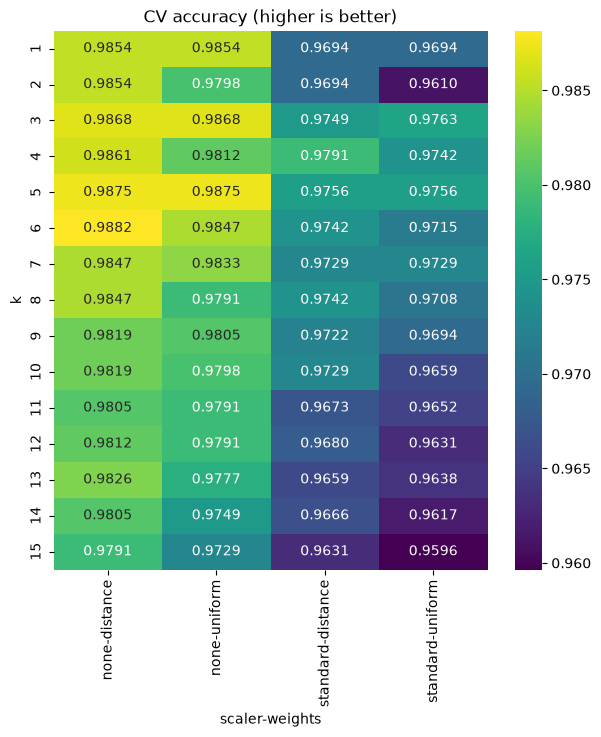

In [96]:
# 搜尋：k × weights × scaler（共 15 × 2 × 2 = 60 組，KNN 不用訓練，很快）
param_grid = {
    "knn__n_neighbors": list(range(1, 16)),
    "knn__weights": ["uniform", "distance"],
    "scaler": ["passthrough", StandardScaler()],
}
gs = GridSearchCV(knn_pipe, param_grid, cv=cv, scoring="accuracy", n_jobs=-1)
gs.fit(X_train, y_train)

res = pd.DataFrame(
    {
        "k": gs.cv_results_["param_knn__n_neighbors"].astype(int),
        "weights": gs.cv_results_["param_knn__weights"].astype(str),
        "scaler": [
            "standard" if isinstance(s, StandardScaler) else "none"
            for s in gs.cv_results_["param_scaler"]
        ],
        "mean": gs.cv_results_["mean_test_score"],
        "std": gs.cv_results_["std_test_score"],
    }
)
print("best_params_：", gs.best_params_, "  CV accuracy：", round(gs.best_score_, 4))

tbl = res.pivot_table(index="k", columns=["scaler", "weights"], values="mean")
fig, ax = plt.subplots(figsize=(7, 7))
sns.heatmap(tbl, annot=True, fmt=".4f", cmap="viridis", ax=ax)
ax.set_title("CV accuracy (higher is better)")
plt.show()

In [97]:
# one-standard-error rule：跟最佳差距不到一個標準差的候選中，挑「最簡單」的
best = res.loc[res["mean"].idxmax()]

# TODO 15（程式）
#   - ok：mean ≥ best.mean − best.std 的所有列（accuracy 越高越好，方向跟第三章 log loss 相反）
#   - choice：ok 裡最簡單的一列。KNN 的「簡單」：k 最大優先；k 相同時 uniform 優先（比 distance 簡單）、
#     scaler 為 "none" 優先（少一個前處理）
#   - 提示：sort_values(["k", "weights", "scaler"], ascending=[False, False, True]).iloc[0]
#     （字串排序："uniform" > "distance"、"none" < "standard"，想想 ascending 為什麼這樣設）
ok = res[res["mean"] >= best["mean"] - best["std"]]
choice = ok.sort_values(by=["k", "weights", "scaler"], ascending=[False, False, True]).iloc[0]

print("CV 最佳 ：", best.to_dict())
print("1-SE 選擇：", choice.to_dict())
print("✅ 1-SE 應選到 k = 13、weights = distance、scaler = none")

from sklearn.base import clone

model_1se = (
    clone(knn_pipe)
    .set_params(
        knn__n_neighbors=int(choice["k"]),
        knn__weights=choice["weights"],
        scaler=StandardScaler() if choice["scaler"] == "standard" else "passthrough",
    )
    .fit(X_train, y_train)
)

CV 最佳 ： {'k': 6, 'weights': 'distance', 'scaler': 'none', 'mean': 0.9881629887727449, 'std': 0.0056667269604748095}
1-SE 選擇： {'k': 13, 'weights': 'distance', 'scaler': 'none', 'mean': 0.9826050135501354, 'std': 0.00491740643306307}
✅ 1-SE 應選到 k = 13、weights = distance、scaler = none


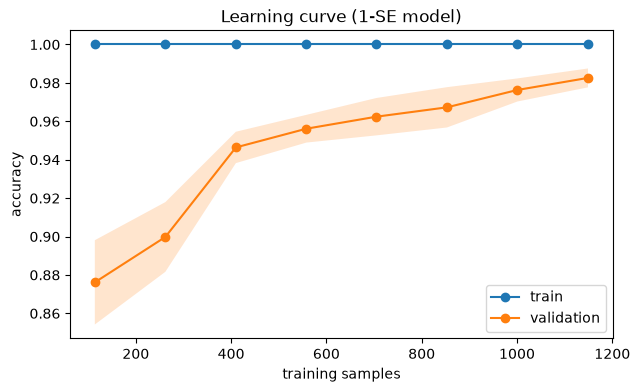

,n,train,val,val_std
0,114,1.0,0.8761,0.0219
1,262,1.0,0.8998,0.0181
2,410,1.0,0.9464,0.0082
3,558,1.0,0.9562,0.0072
4,705,1.0,0.9624,0.0097
5,853,1.0,0.9673,0.0105
6,1001,1.0,0.9763,0.0060
7,1149,1.0,0.9826,0.0049


In [98]:
# 學習曲線：再多一點資料會更好嗎？
sizes, tr_s, va_s = learning_curve(
    model_1se,
    X_train,
    y_train,
    cv=cv,
    scoring="accuracy",
    train_sizes=np.linspace(0.1, 1.0, 8),
)
fig, ax = plt.subplots(figsize=(7, 4))
for name, s in [("train", tr_s), ("validation", va_s)]:
    ax.plot(sizes, s.mean(1), "o-", label=name)
    ax.fill_between(sizes, s.mean(1) - s.std(1), s.mean(1) + s.std(1), alpha=0.2)
ax.set_xlabel("training samples")
ax.set_ylabel("accuracy")
ax.set_title("Learning curve (1-SE model)")
ax.legend()
plt.show()
display(
    pd.DataFrame(
        {"n": sizes, "train": tr_s.mean(1), "val": va_s.mean(1), "val_std": va_s.std(1)}
    ).round(4)
)

### TODO 16（問答）

> **(1)** 看 heatmap：

> **(a)** standard 兩欄的數字大約落在多少？none 兩欄呢？差多少？跟實驗 2 的 LOO（raw 0.988 vs standard 0.974）一致嗎？

standard：0.960–0.979；none：0.973–0.988。同一個 $k$ 比較，standard 大約低 1 個百分點 → 與實驗 2 一致。（GridSearch 把「要不要標準化」當成超參數，用 CV 得到了跟 LOO 實驗相同的結論。）

> **(b)** $k = 1$ 時，uniform 與 distance 兩欄的數字完全一樣。只有 1 個鄰居投票時，它的票是 1 還是 $1/d$，會改變誰贏嗎？

不會。只有一個類別拿到票，不論票數是 1 還是 $1/d$（任何正數），argmax 都是它 → 兩種 weights 在 $k = 1$ 時是同一個模型。

> **(c)** $k$ 大時（例如 $k = 15$），uniform 和 distance 哪一欄比較高？為什麼距離加權在 $k$ 大時比較有幫助？（提示：TODO 10 (3)，遠處的鄰居只拿到小票）

distance 較高（$k = 15$：0.979 vs 0.973）。uniform 時，第 15 近的鄰居（可能已經跑到別類的區域）和最近的鄰居票數一樣；distance 時，越近的鄰居票越大，遠處的鄰居只拿到小票 → 越近越可能同類，由它們主導。

效果：$k$ 大時 uniform 的「鄰域太大、被別類稀釋」（欠擬合的來源）被距離加權部分抵銷，所以 $k$ 大時退化得較慢（TODO 10 (3)）。

> **(2)** 1-SE rule：

> **(a)** CV 最佳是哪一組？mean 與 std 各是多少？1-SE 的門檻 = mean − std = ?

CV 最佳：$k = 6$、distance、不標準化；mean = 0.9882、std = 0.0057。

$$\text{1-SE 門檻} = 0.9882 - 0.0057 = 0.9825$$

**修正**：門檻要用「CV 最佳那一組」的 mean 與 std，不是 1-SE 選到那一組的 0.9826 − 0.0049。

> **(b)** 1-SE 選了哪一組？它的 mean 跟最佳差多少？差距相當於幾個 std？

$k = 13$、distance、不標準化，mean = 0.9826。差距 $= 0.9882 - 0.9826 = 0.0056$ → $0.0056 / 0.0057 \approx 0.98$ 個 std（不是 1–2 個）。剛好低於一個 std，所以勉強落在門檻（0.9825）內 —— 1-SE 選的是「在門檻內、$k$ 最大」的那組，通常就會貼著門檻。

> **(c)** 每個 fold 約 287 筆，accuracy 的 1 筆 ≈ 0.35%。最佳與 1-SE 的差距，相當於每個 fold 多錯幾筆？這麼小的差距，算「真的比較差」嗎？

衡量方式：把 accuracy 的差距換算成「筆數」—— 差距 × 每個 fold 的筆數：

$$0.0056 \times 287 \approx 1.6 \text{ 筆}$$

平均每個 fold 只多錯 1–2 筆。對照雜訊：最佳那組的 std = 0.0057，也約等於 1.6 筆 —— 光是換一個 fold，分數就會上下浮動這麼多。→ 差距跟「隨機浮動」一樣大，統計上不能說 1-SE 真的比較差；但也不能說兩者一樣好，只是「分不出來」。

> **(d)** 選較大的 $k$ 的好處是邊界平滑、對雜訊與標錯的樣本較穩健。Digits 的雜訊低（TODO 10 (2)），這個好處在這裡重要嗎？你會選 1-SE 還是 CV 最佳？兩個都說得通，重點是說出理由。

不太重要：Digits 雜訊低、同類樣本很密（98.8% 的最近鄰同類），$k$ 小的變異代價本來就小，平滑的好處有限。

**修正**：「維度不是均勻散開」說的是維度詛咒（TODO 12 (3)），跟「對雜訊穩健」是不同的問題。

**選 CV 最佳（$k = 6$）是合理的，但理由要修正**：1-SE 選的 $k = 13$ 也是用 CV（沒看過的樣本）評估的，兩者在「用沒看過的樣本」這點上一樣。更好的理由是：1-SE 的精神是「用一點點分數換更簡單、更便宜的模型」；第三章的 1-SE 少用了 7 個特徵，有實際好處。KNN 的 $k = 13$ 和 $k = 6$ 預測成本幾乎一樣（都要算全部距離）、也沒有更好解釋 → 「簡單」換不到實際好處，加上資料雜訊低、平滑的好處小 → 不如選分數最高的。

反方理由（選 1-SE 也說得通）：預期未來資料比訓練資料更雜（不同人寫、掃描品質差）時，較大的 $k$ 較穩健。

> **(3)** 學習曲線：

> **(a)** train 為什麼每個 $n$ 都是 1.0？（提示：1-SE 模型用的是哪一種 weights？TODO 10 (1)）這條 train 線還能拿來判斷過擬合嗎？

1-SE 模型用 `weights="distance"`。在訓練集上評估時，每一筆都在訓練資料裡、與自己的距離 = 0 → 觸發「有距離 0 的鄰居時只有它投票」（TODO 6）→ 只有自己投票 → 永遠猜對 → 1.0（同 TODO 10 (1)）。不能拿來判斷過擬合：train 恆為 1.0、沒有任何資訊量，只能看 val 的趨勢。

> **(b)** val 從最小的 $n$ 到最大的 $n$ 怎麼變化？最後兩、三點還在上升，還是已經平了？

0.876（$n = 114$）→ 0.983（$n = 1149$），一路上升；最後一段 0.9763 → 0.9826 仍上升 0.6%，大於 std（0.005）→ 還沒平，再多給資料很可能還會進步。（KNN 是無母數模型：資料越多，「附近剛好有很像的樣本」的機會越大。）

> **(c)** KNN 的預測成本與記憶體都與 $n_\text{train}$ 成正比（TODO 8 (2)）。訓練資料加倍，accuracy 可能再升一點，但每次預測的時間、模型佔的記憶體各變成幾倍？這跟邏輯回歸「多給資料只讓訓練變久」有什麼不同？

**修正**：$n(n-1)$ 是「訓練集每一對之間」的距離數，那是 LOO 的成本；這題問的是「預測一筆新資料」。

| | KNN | 邏輯回歸 |
| --- | --- | --- |
| 預測一筆 | 跟每一筆訓練資料算距離（$n_\text{train}$ 個）→ 資料加倍，約 **2 倍** | $O(d)$，不變 |
| 記憶體 | 模型就是整份訓練資料 $n_\text{train} \times d$ → **2 倍** | $d + 1$ 個參數，不變 |
| 訓練 | 不變（只存資料） | GD 每步 $O(nd)$ → 2 倍 |

→ KNN 把「資料變多」的代價放在每一次預測上，參數模型則只在訓練時付一次。

---
## 6. 測試集評估

模型都已經用 CV 決定好，測試集只評估一次。
另外放一個第三章的模型當跨章節對照：Softmax 邏輯回歸（標準化 + C=1，未調參）。

/Users/cya/ml-dl-llm/.venv/lib/python3.12/site-packages/sklearn/neighbors/_nearest_centroid.py:241: UserWarning: self.within_class_std_dev_ has at least 1 zero standard deviation.Inputs within the same classes for at least 1 feature are identical.
  warnings.warn(


,accuracy,precision,recall,f1,roc_auc
Dummy prior,0.1000,0.0100,0.1000,0.0182,0.5000
NearestCentroid (sklearn),0.8778,0.8772,0.8773,0.8760,0.9921
KNN k=5 (scratch),0.9833,0.9834,0.9831,0.9830,0.9983
KNN k=5 (sklearn),0.9833,0.9834,0.9831,0.9830,0.9983
KNN CV-best (sklearn),0.9833,0.9837,0.9831,0.9831,0.9983
KNN 1-SE (sklearn),0.9806,0.9815,0.9802,0.9801,0.9981
"Softmax LogReg C=1 (sklearn, ref)",0.9722,0.9721,0.9719,0.9719,0.9991


,model,accuracy,time,precision,recall,f1,roc_auc,params,notes
0,KNN k=5 (scratch),0.9833,2026-10-24 14:30,0.9834,0.9831,0.9830,0.9983,"{""k"": 5, ""weights"": ""uniform""}",NaN
1,KNN k=5 (sklearn),0.9833,2026-10-24 14:30,0.9834,0.9831,0.9830,0.9983,"{""k"": 5}",NaN
2,KNN CV-best (sklearn),0.9833,2026-10-24 14:30,0.9837,0.9831,0.9831,0.9983,"{""n_neighbors"": 6, ""weights"": ""distance"", ""sca...",NaN
3,KNN 1-SE (sklearn),0.9806,2026-10-24 14:30,0.9815,0.9802,0.9801,0.9981,"{""k"": 13, ""weights"": ""distance"", ""scaler"": ""no...",NaN
4,"Softmax LogReg C=1 (sklearn, ref)",0.9722,2026-10-24 14:30,0.9721,0.9719,0.9719,0.9991,"{""C"": 1.0}",NaN
5,NearestCentroid (sklearn),0.8778,2026-10-24 14:30,0.8772,0.8773,0.8760,0.9921,NaN,NaN
6,Dummy prior,0.1000,2026-10-24 14:30,0.0100,0.1000,0.0182,0.5000,NaN,NaN


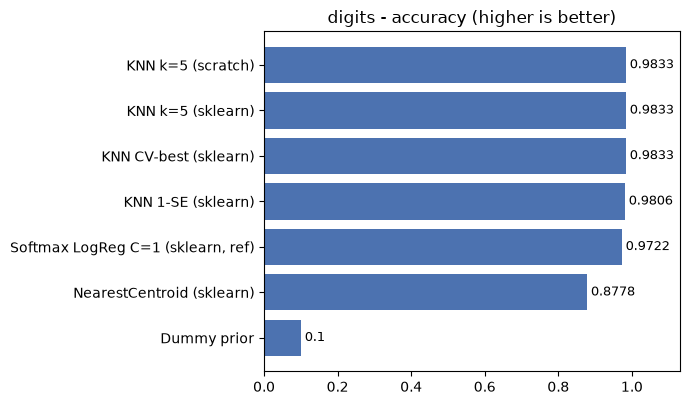

In [100]:
from sklearn.linear_model import LogisticRegression
from ml_dl_llm.metrics import classification_metrics
from ml_dl_llm.results import compare, log_result

BENCH = "digits"
bp = {
    k.split("__")[-1]: (str(v) if not isinstance(v, (int, float, str)) else v)
    for k, v in gs.best_params_.items()
}

dummy = DummyClassifier(strategy="prior").fit(X_train, y_train)
centroid = NearestCentroid().fit(X_train, y_train)
logreg = Pipeline(
    [("scaler", StandardScaler()), ("lr", LogisticRegression(max_iter=5000))]
).fit(X_train, y_train)

# 名稱: (預測, 機率或 None, 要記下的參數)
eval_models = {
    "Dummy prior": (dummy.predict(X_test), dummy.predict_proba(X_test), {}),
    "NearestCentroid (sklearn)": (
        centroid.predict(X_test),
        centroid.predict_proba(X_test),
        {},
    ),
    "KNN k=5 (scratch)": (
        scratch.predict(Xte),
        scratch.predict_proba(Xte),
        {"k": 5, "weights": "uniform"},
    ),
    "KNN k=5 (sklearn)": (
        knn_pipe.predict(X_test),
        knn_pipe.predict_proba(X_test),
        {"k": 5},
    ),
    "KNN CV-best (sklearn)": (
        gs.best_estimator_.predict(X_test),
        gs.best_estimator_.predict_proba(X_test),
        bp,
    ),
    "KNN 1-SE (sklearn)": (
        model_1se.predict(X_test),
        model_1se.predict_proba(X_test),
        {
            "k": int(choice["k"]),
            "weights": choice["weights"],
            "scaler": choice["scaler"],
        },
    ),
    "Softmax LogReg C=1 (sklearn, ref)": (
        logreg.predict(X_test),
        logreg.predict_proba(X_test),
        {"C": 1.0},
    ),
}

test_scores = {}
for name, (pred, prob, params) in eval_models.items():
    m = classification_metrics(y_test, pred, prob)
    test_scores[name] = m
    log_result(BENCH, name, m, **params)

display(pd.DataFrame(test_scores).T)
compare(BENCH, "accuracy")

---
## 7. 診斷

KNN 最大的優點之一是**可以用例子解釋**：每個預測都能指出「因為它長得像這幾張訓練影像」。

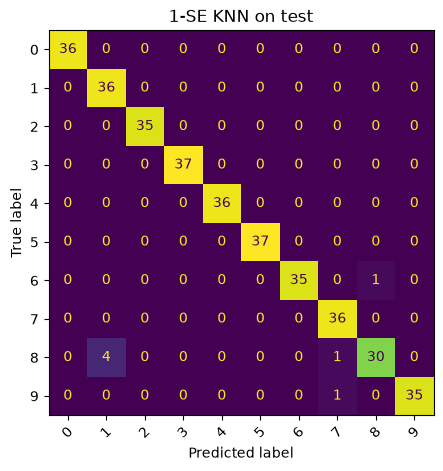

測試集錯 7 筆 / 360


In [101]:
from ml_dl_llm.metrics import plot_confusion_matrix

pred_te = model_1se.predict(X_test)
plot_confusion_matrix(y_test, pred_te)
plt.title("1-SE KNN on test")
plt.show()

wrong_idx = np.flatnonzero(pred_te != yte)
print(f"測試集錯 {len(wrong_idx)} 筆 / {len(yte)}")

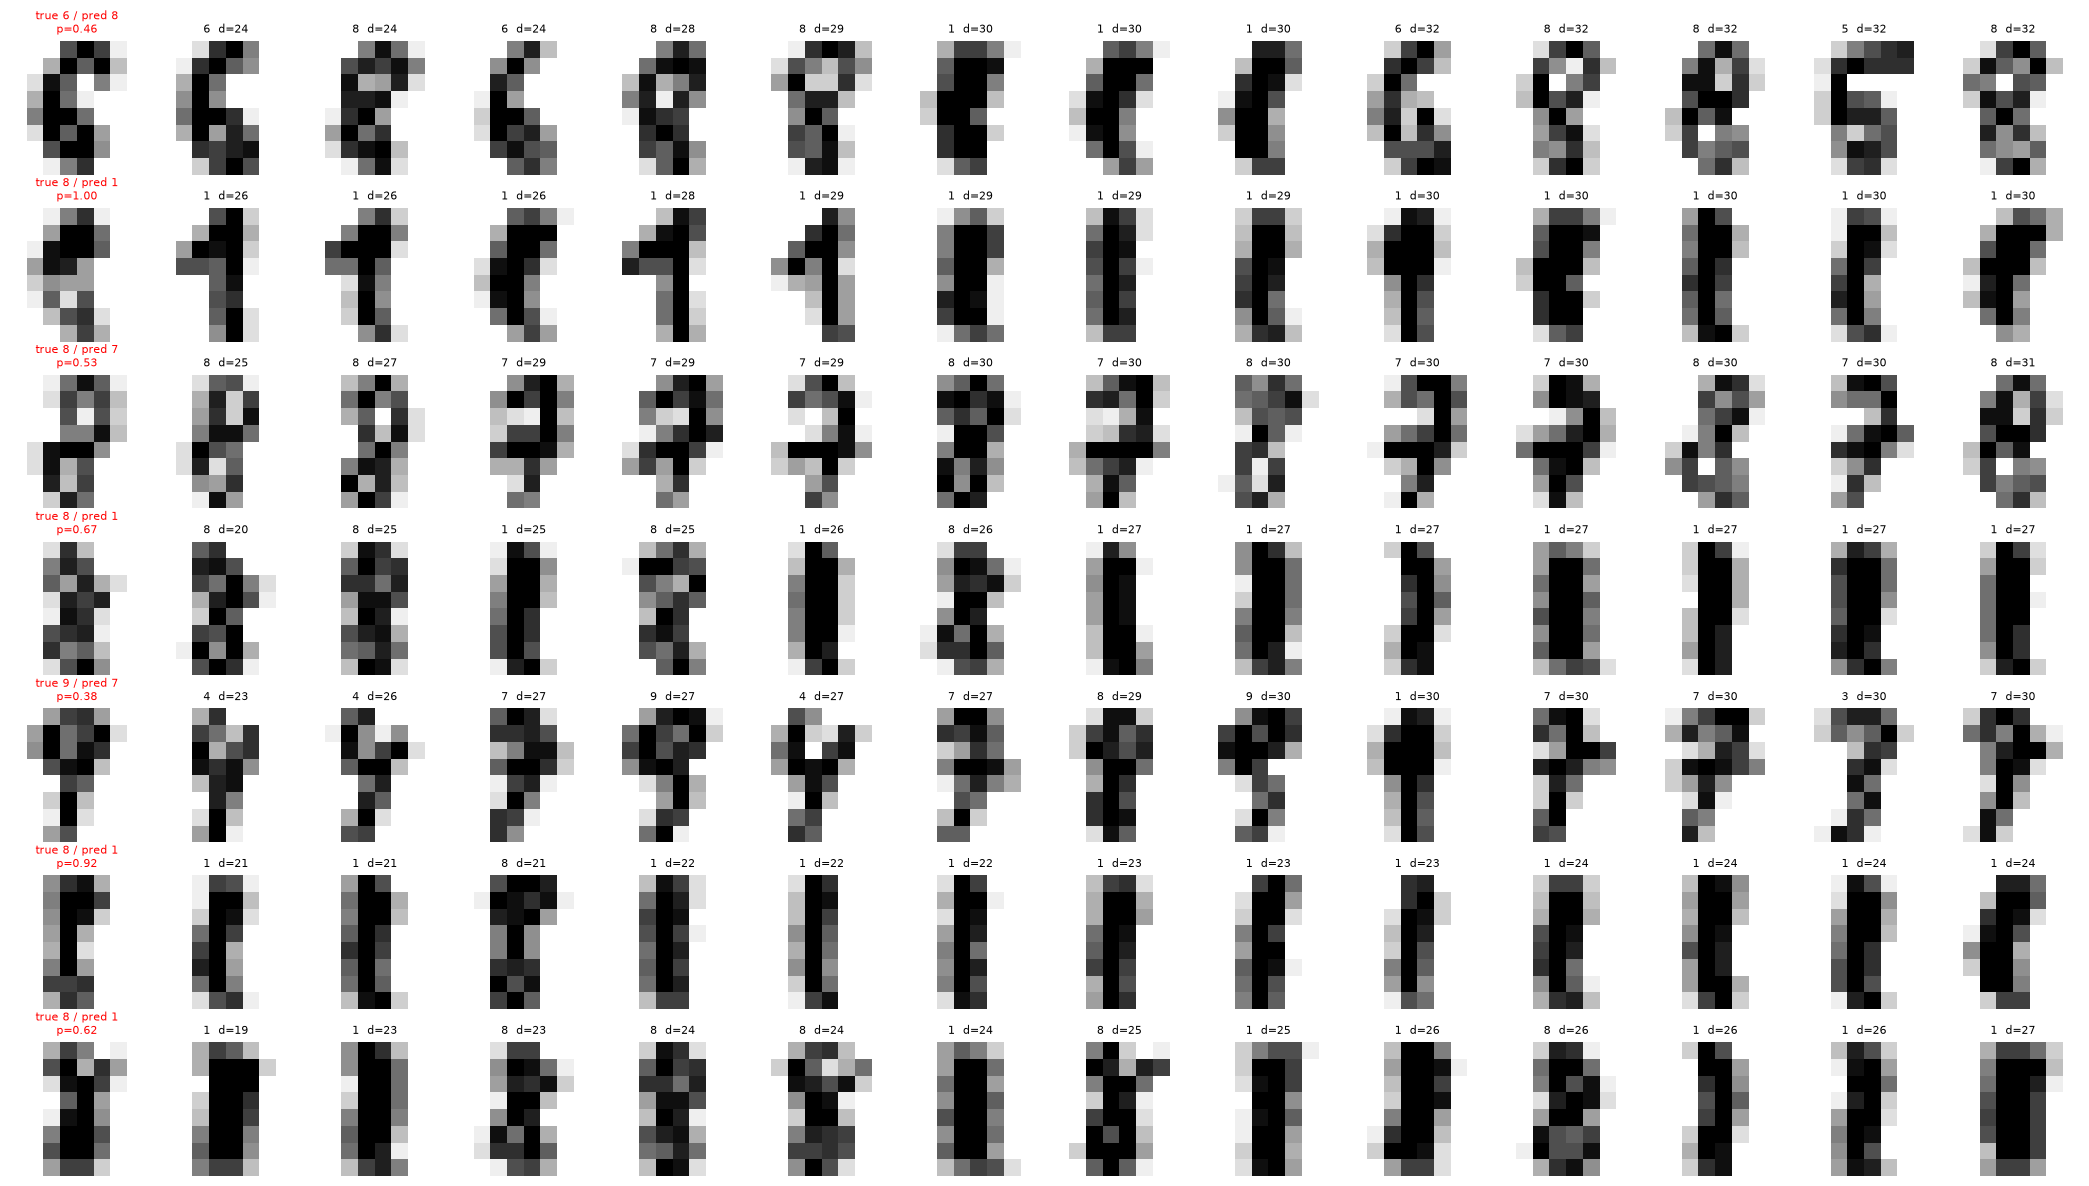

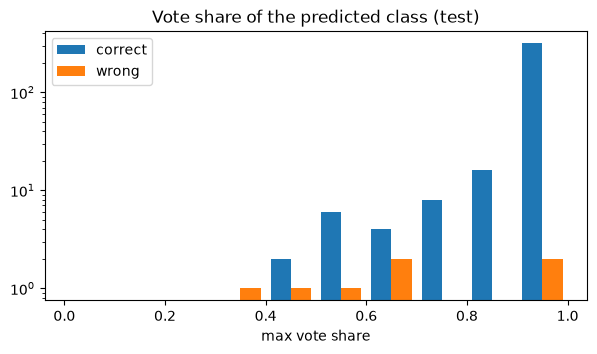

最近鄰距離中位數：答對 16.4 ／答錯 23.5


In [102]:
# 每一筆錯誤：查詢影像 + 它在訓練集中的 k 個最近鄰（標題 = 鄰居的標籤與距離）
k_show = int(choice["k"])
X_q = model_1se[0].transform(X_test) if choice["scaler"] == "standard" else X_test
dist_w, nb_w = model_1se[-1].kneighbors(
    X_q.iloc[wrong_idx] if hasattr(X_q, "iloc") else X_q[wrong_idx]
)
proba_te = model_1se.predict_proba(X_test)

fig, axes = plt.subplots(
    len(wrong_idx),
    k_show + 1,
    figsize=(1.5 * (k_show + 1), 1.7 * len(wrong_idx)),
    squeeze=False,
)
for r, i in enumerate(wrong_idx):
    axes[r, 0].imshow(Xte[i].reshape(8, 8), cmap="gray_r", vmin=0, vmax=16)
    axes[r, 0].set_title(
        f"true {yte[i]} / pred {pred_te[i]}\np={proba_te[i].max():.2f}",
        fontsize=8,
        color="r",
    )
    for c in range(k_show):
        j = nb_w[r, c]
        axes[r, c + 1].imshow(Xtr[j].reshape(8, 8), cmap="gray_r", vmin=0, vmax=16)
        axes[r, c + 1].set_title(f"{ytr[j]}  d={dist_w[r, c]:.0f}", fontsize=8)
for ax in axes.ravel():
    ax.axis("off")
fig.tight_layout()
plt.show()

# 最高得票比例（模型的「把握」）：答對 vs 答錯
fig, ax = plt.subplots(figsize=(7, 3.5))
top = proba_te.max(axis=1)
ax.hist(
    [top[pred_te == yte], top[pred_te != yte]],
    bins=np.linspace(0, 1, 11),
    label=["correct", "wrong"],
    log=True,
)
ax.set_xlabel("max vote share")
ax.legend()
ax.set_title("Vote share of the predicted class (test)")
plt.show()

# 最近鄰距離：答錯的樣本是不是離訓練資料特別遠？
d1 = model_1se[-1].kneighbors(X_q, n_neighbors=1)[0].ravel()
print(
    "最近鄰距離中位數：答對",
    round(float(np.median(d1[pred_te == yte])), 1),
    "／答錯",
    round(float(np.median(d1[pred_te != yte])), 1),
)

### TODO 17（問答，本章總結）

> **(1)** 混淆矩陣：

> **(a)** 數一數非對角線的格子：哪一格（真實 → 預測）最多？錯誤主要集中在哪幾個數字？

真實 8 → 預測 1 最多（4 筆）。7 筆錯誤中有 5 筆的真實標籤是 8（8→1 ×4、8→7 ×1），其餘是 6→8、9→7。→ 錯誤高度集中在「8」：8 既容易被認錯（5 筆），也被當成別人的答案（6→8）。

> **(b)** 對照 TODO 1 (3) 的預測（與 8 有關的組合、3–9）：哪些猜中了、哪些沒有？

- 猜中：與 8 有關，而且正是平均影像第二接近的 1–8（21.4）。
- 沒猜中：平均影像「最」接近的 3–9（20.9）在測試集上一筆都沒錯。
- → 印證 TODO 1 (3)：平均影像接近只是粗略線索；3 和 9 的平均很像，但個別樣本在邊界上不太交錯。

> **(2)** 看「錯誤樣本 + 最近鄰」那張圖：

> **(a)** 左邊的查詢影像，人眼看會說是什麼數字？跟真實標籤一樣嗎？

真實是 8 的那幾筆，大多看得出是 8，只是寫得很「窄」—— 兩個圈被擠成細長的一條；6→8、9→7 那兩筆則本身就不太好認。

> **(b)** 它的鄰居大多是哪個數字？鄰居跟查詢影像「哪裡像」？

8→1 的那幾筆，鄰居幾乎全是 1。像的地方是「墨水分布」：窄的 8 把筆畫集中在中間 2–3 欄、上下都有，跟一條直直的 1 在像素格上重疊很多；8 的兩個圈在 8×8 的解析度下只剩幾格淡淡的灰，逐格比對時份量很小。

**修正**：不是對稱性 —— 像素距離不認識「對稱」這種形狀概念，它只會一格一格比亮度。

> **(c)** 把每一筆錯誤歸到：① 寫法本身模稜兩可；② 標籤可疑；③ 像素距離的盲點。哪一類最多？

| 類別 | 筆數 | 例子 |
| --- | --- | --- |
| ③ 像素距離的盲點 | **4（最多）** | 窄的 8 → 1：人一看就知道有兩個圈，但它跟「寬的 8」逐格比差很多（筆畫位置不同），反而跟 1 逐格比較像 |
| ① 模稜兩可 | 3 | 6→8、9→7、8→7：鄰居各類混雜、得票比例約 0.4–0.5，人也會猶豫 |
| ② 標籤可疑 | 0 | 這次沒有明顯的例子 |

**修正**：「圖片寫法的問題」要再分清楚 —— 寫得「模稜兩可」是 ①；寫法正常、只是寬窄不同就被認錯，是 ③。③ 的錯在距離的定義，不在資料。

> **(d)** 兩個統計：得票比例（模型的把握）答錯的比答對的高還是低？最近鄰距離中位數答錯的比答對的遠還是近？「離所有訓練資料都比較遠」代表這張影像有什麼特性？

（題意：比較「答對的樣本」與「答錯的樣本」在這兩個數字上的差別。）

| | 答對 | 答錯 |
| --- | --- | --- |
| 得票比例（預測那一類拿到的票佔多少） | 中位數 1.0；81% 是 1.0、90% ≥ 0.9（鄰居幾乎全部同意） | 7 筆中 5 筆只有 0.38–0.67（鄰居意見分歧） |
| 最近鄰距離中位數 | 16.4 | 23.5 |

- 得票比例低，是「這筆可能錯」的警訊。（例外：有一兩筆窄的 8 得票接近 1.0 —— 鄰居全是 1，模型很有把握地錯，這正是 ③ 的特徵。）
- 答錯的樣本離「最像它的訓練樣本」也比較遠。「離所有訓練資料都比較遠」代表這張影像很少見、不典型 —— 訓練集裡沒有長得很像它的例子，KNN 只能拿「沒那麼像」的鄰居來投票，結果就不可靠。
- 實務用途：兩個數字都可以當「不確定」的訊號 —— 得票比例低或最近鄰距離大的樣本，可以拒絕自動判斷、交給人看（reject option）。

> **(3)** 瓶頸在哪？

> **(a)** 第 5 節已經搜過 $k$、weights、scaler，最好也只到 CV 0.988。如果錯誤大多屬於 ③，再換 $k$ 或投票方式，能修正嗎？為什麼？

不能。③ 的問題是「最近的鄰居本身就是錯的類別」（窄的 8 最近的十幾個鄰居都是 1）。$k$ 與投票方式只是決定「怎麼統計這些鄰居的票」，鄰居是誰由距離決定 —— 鄰居錯了，怎麼投都錯。第 5 節搜過所有組合也只到 0.988，就是這個原因。

> **(b)** 兩個方向（讓距離容忍平移／旋轉／粗細；先轉成筆畫結構的特徵再做 KNN）改變的是「資料」、「特徵／距離的定義」還是「模型（$k$、投票）」？

兩者改變的都是**「特徵／距離的定義」**，不是資料品質，也不是模型（$k$、投票）：

- 容忍平移、旋轉、粗細：換一個「什麼叫做像」的定義（例如 tangent distance、先對齊再比）。
- 先轉成筆畫結構的特徵（例如 CNN 學到的 embedding）：換一個空間，讓「同一個數字」在新空間裡靠在一起，再用歐氏距離。

data augmentation（把訓練圖平移、縮放、變粗變細後加入訓練集）是第三個方向，改變的是**「資料」**：讓訓練集裡本來就有「窄的 8」，窄的 8 就有很像的同類鄰居了。也有效，代價是訓練集變大、KNN 預測變慢。

> **(c)** 結論：這一章 KNN 的瓶頸主要在哪裡？

在**「距離的定義」**：逐格像素的歐氏距離不懂形狀（圈、筆畫結構），只要寬窄、位置不同就判定為不像。資料本身品質不差（雜訊低、標籤可靠），模型的超參數也已經調到頂。

**修正**：不是「距離的計算」—— 計算本身正確而且很快；問題在於用這個距離衡量「像不像」不夠好。

> **(4)** 跟第三章的 softmax 邏輯回歸比：

> **(a)** KNN 1-SE 與 Softmax LogReg 的 test accuracy 各多少？測試集 360 筆（1 筆 ≈ 0.28%），差幾筆？

KNN 1-SE 0.9806、Softmax LogReg 0.9722（**修正**：0.9815 是 1-SE 的 precision）。差距 $0.0083 \times 360 \approx 3$ 筆（7 筆錯 vs 10 筆錯）；KNN CV 最佳 0.9833 則差 4 筆。注意：360 筆的測試集上差 3–4 筆，只能說 KNN「可能」略好；而且 LogReg 這裡沒有調參，只是參考。

> **(b)** 比較表

| | KNN | Softmax 邏輯回歸 |
| --- | --- | --- |
| 訓練成本 | 幾乎為 0（只存資料） | 要最佳化：$O(\text{迭代次數} \cdot n \cdot d \cdot K)$ |
| 預測成本（每筆） | 高：$O(n_\text{train} \cdot d)$，要跟每筆訓練資料比 | 低：$O(d \cdot K)$，一次矩陣乘法 |
| 模型大小 | 整份訓練資料 $n_\text{train} \times d$ | $K \times (d + 1)$ 個參數 |
| 怎麼解釋一個預測 | 用「例子」：因為它最像這幾張訓練圖（可以直接秀出鄰居） | 用「係數」：每個像素對每一類加減多少分（$W$ 的每一欄可畫成 8×8 圖） |
| 決策邊界的形狀 | 非線性、任意形狀，由局部的訓練點決定（$k$ 小時很彎） | 線性：任兩類之間的邊界是超平面 $(w_i - w_j)\cdot x + (b_i - b_j) = 0$ |
| 無關特徵／尺度 | 無關特徵直接加進距離，傷害大；縮放 = 改變距離權重，直接改變預測 | 無關特徵的係數可學成約 0；不加正則化時縮放不影響預測（只影響收斂） |

（「covariants」→ 共變量／特徵 covariates；「決策邊界的形狀」問的是邊界是直的（超平面）還是可以彎曲。）

> **(c)** 什麼情況選 KNN？什麼情況選邏輯回歸？

「先看資料」是對的，但可以說出要看什麼：

| 選 KNN | 選邏輯回歸 |
| --- | --- |
| 資料量中等、預測次數不多 | 資料量大或需要即時預測、模型要小 |
| 距離有意義（單位一致或已妥善縮放）、實際維度不高、無關特徵少 | 特徵很多且有不少無關特徵（例如文字的詞袋） |
| 類別邊界彎曲或一類有多種樣子（多峰） | 邊界大致線性 |
| 需要「用例子解釋」 | 需要可信的機率（校準好）或需要用係數解釋 |
| 資料常常新增（不必重新訓練，加進去就好） | |

實務做法：兩個都用 CV 試，再依上面的成本與解釋需求取捨 —— 這就是「先看過資料」的具體做法。

---
## 8. 本章小結

### 方法與結果

Digits（train 1,437 / test 360；CV = 5-fold 分層；LOO = leave-one-out）。

| 方法 | 做法 | 關鍵性質 | CV accuracy | test accuracy |
| --- | --- | --- | --- | --- |
| Dummy prior | 輸出類別比例 | log loss = 標籤分布的熵 = ln 10 ≈ 2.30 | 0.101 ± 0.000 | 0.100 |
| NearestCentroid | 每類 1 個平均影像，找最近的中心 | 假設每類是單一球狀團；邊界分段線性 | 0.908 ± 0.010 | 0.878 |
| KNN k=5（手寫） | 展開式距離矩陣 + argpartition + 投票 | 與 sklearn 鄰居距離、機率、預測完全一致 | LOO 0.986 | 0.983 |
| KNN k=5（sklearn 預設） | brute force | `algorithm="auto"` 在 64 維選 brute | 0.988 ± 0.008 | 0.983 |
| KNN CV 最佳 | k = 6、distance、不標準化 | GridSearch：k × weights × scaler | 0.988 ± 0.006 | 0.983 |
| KNN 1-SE | k = 13、distance、不標準化 | 差距 0.98 個 std（每 fold 約 1.6 筆） | 0.983 ± 0.005 | 0.981 |
| Softmax LogReg（對照，未調參） | 標準化 + C = 1 | 線性邊界 | — | 0.972 |

- 所有 KNN 版本在測試集上只錯 6–7 筆，彼此分不出優劣；比邏輯回歸多對 3–4 筆，但 360 筆的測試集上這個差距只算「可能略好」。
- 錯誤集中在 8（7 筆中 5 筆），主要是「寫得窄的 8 → 1」：像素距離的盲點，不是超參數能修的。

### 核心觀念

1. **KNN 沒有參數**：`fit` 只存資料（lazy learning），所有計算延後到 `predict`。是無母數模型：模型大小與每次預測成本 O(n_train · d) 都隨資料量成長；參數模型則是訓練貴、預測 O(d)。
2. **距離矩陣**：‖a − b‖² = ‖a‖² + ‖b‖² − 2a·b，一次矩陣乘法算完（`[:, None]`／`[None, :]` 廣播）。代價是災難性抵消：大數相減剩小數，誤差跟著大數走；資料先置中（A、B 減同一個平均）即可避免。像素是整數、值小於 2⁵³ 時剛好完全精確。
3. **找前 k 個**：`argpartition` O(m) 只保證「是最小的 k 個」、不保證順序，再對 k 個 `argsort`；「每列各自照位置取值」一律用 `take_along_axis(axis=1)`，`v[order]` 是取整列。距離平手時鄰居編號依實作而定：前 k 名內部平手不影響預測，第 k／k+1 名的邊界平手才可能影響。
4. **投票**：uniform 每人 1 票、distance 1/d（距離 0 時只有它投票）；加總用 `np.add.at` 或 `np.bincount`（one-hot 的暫存陣列大 k 倍）。KNN 的機率只能是 1/k 的整數倍。
5. **k 的方向**：k 小 = 複雜（邊界跟著個別點走、低偏差高變異、左端過擬合）；k 大 = 簡單（平滑、高偏差、右端欠擬合），是第三章 C 的左右鏡像。複雜度指「對個別訓練點的敏感度」，不是計算量。
6. **評估 KNN**：resubstitution 沒有意義（k = 1 或 distance 加權時恆為 1.0；學習曲線的 train 線也是）。LOO 對 KNN 幾乎免費：距離矩陣對角線設 ∞；邏輯回歸則要重訓 n 次 —— LOO 便宜與否取決於模型能否便宜地「忘掉」一筆資料。k = n − 1 的 LOO 會讓每一筆的類別少 1 票 → accuracy 0。
7. **尺度 = 距離的權重**：每個特徵佔平方距離的份量 ∝ 縮放後的變異。單位不同（Breast Cancer）必須標準化；單位相同且變異有意義（像素）時，標準化會把近乎恆定的邊緣像素放大成雜訊（1 → 37.9 個標準差），LOO 0.988 → 0.974。跟第三章的理由不同：那裡是收斂速度與 L2 公平性，這裡直接改變模型。
8. **維度詛咒**：平方距離是 d 項之和，平均 ∝ d、波動 ∝ √d → 高維時所有距離擠在一起（d = 1024 時最遠只比最近遠 12%），最近鄰失去意義。無關特徵的「波動」會蓋過訊號的「差距」（加 512 維雜訊：1-NN 0.988 → 0.670）；KNN 無法像邏輯回歸把無關特徵的係數學成 0。
9. **Intrinsic dimension**：Digits 有 64 欄，但像素高度相關，實際只在低維結構上變化（PCA 21 個成分 90%、相對對比 3.30，像均勻資料的 d ≈ 8）→ 沒被維度詛咒打敗。維度詛咒看的是實際佔據的維度，不是欄位數。
10. **搜尋結構**：KD-Tree 靠「整塊盒子比 r 遠就跳過」，但樹只有約 log₂ n 層，高維時大部分軸沒被切、下界遠小於 r → 跳不掉，比 brute（一次 BLAS 矩陣乘法）還慢（d = 64 慢約 70 倍）。億級資料、數百維時用近似最近鄰（ANN：HNSW、IVF、PQ、FAISS），放棄精確（recall@k）換速度。
11. **選模型的指標**：KNN 的機率只是計票，log loss 主要在量「正確類別 0 票」的樣本（−ln eps ≈ 36），會把 k 推大（k ≈ 10）；選 KNN 的 k 用 accuracy。第三章用 log loss 選 C 合理，因為邏輯回歸的機率就是用 log loss 訓練出來的。
12. **1-SE rule 的前提**：統計上分不出優劣（差距 ≈ 1.6 筆／fold）時選簡單的模型，但要看「簡單」換到什麼。第三章少了 7 個特徵；KNN 的 k = 13 與 k = 6 成本相同、解釋性相同，加上 Digits 雜訊低，選 CV 最佳同樣合理。
13. **診斷**：KNN 可以「用例子解釋」每個預測。得票比例低、最近鄰距離大（答錯 23.5 vs 答對 16.4）都是「可能錯」的訊號，可用來拒絕自動判斷。錯誤的鄰居本身就錯時，k 與投票救不了 → 瓶頸在距離的定義（逐格像素不懂形狀）。

### 待補強（之後回來可以學）

**距離與表示**
- [ ] 馬氏距離（Mahalanobis）與 metric learning（NCA：`sklearn.neighbors.NeighborhoodComponentsAnalysis`、LMNN）：從資料學「什麼叫做像」
- [ ] 平移／形變不變的距離：tangent distance、shape context；DTW（第七章 DTW＋KNN）
- [ ] 資料增強（平移、縮放、粗細）對 KNN 的效果與預測成本的取捨
- [ ] 先用 PCA 降維再做 KNN（第 14 章回來比較）；用 CNN embedding 做 KNN（第二章 LeNet 之後）
- [ ] 特徵選擇（`VarianceThreshold`、互資訊）對 KNN 的影響

**搜尋結構**
- [ ] KD-Tree、Ball Tree 的建立與剪枝規則；`leaf_size` 的影響
- [ ] 近似最近鄰（ANN）：LSH、IVF／PQ（FAISS）、HNSW；recall@k 與速度的取捨（第四章 RAG 會用到）

**理論**
- [ ] Cover & Hart（1967）：n → ∞ 時 1-NN 錯誤率 ≤ 2 × 貝氏錯誤率；k → ∞、k/n → 0 時 KNN 一致收斂
- [ ] 維度詛咒的量化：距離集中（concentration of measure）、intrinsic dimension 的估計方法
- [ ] KNN 的有效自由度（≈ n / k）與偏差—變異分解
- [ ] LOO 的閉式捷徑：線性回歸／Ridge 的 eᵢ / (1 − hᵢᵢ)（hat matrix、PRESS）；LOO 在 Dummy 類模型上的怪現象

**評估與決策**
- [ ] KNN 機率的校準（`CalibratedClassifierCV`）；用得票比例／最近鄰距離做 reject option、conformal prediction
- [ ] 小測試集上比較兩個模型：McNemar 檢定、bootstrap 信賴區間

**延伸模型**
- [ ] KNN 回歸（`KNeighborsRegressor`）、Radius Neighbors
- [ ] 用 KNN 做異常偵測（LOF）；KNN 補值（`KNNImputer`）